# 04 — Modelos com o RNA-seq

Notebook equivalente a `src/models/` para os testes com expressão gênica (usuário, 2026-11-12). Usa os mesmos modelos de
`src/models/` e os mesmos 5 folds do DNA (`data/processed/coorte_cv.csv`). Entrada: as matrizes do `02_features`, seção 9
(`data/interim/rna_tpm.parquet`, `rna_contagens.parquet`, `rna_genes.csv`). Progresso em `results/04_models_RNA.log`, com
a memória do processo.

# RNA1 — a logística com o RNA-seq (2026-11-15)

Pré-registro no diário, 2026-11-15, "[RNA1] Pré-registro do RNA1, a logística com o RNA-seq"; confirmado pelo usuário no
mesmo dia.

- **Modelo:** a logística do DNA (`src/models/logistica.py`: C = 1, peso balanceado, `max_iter` 2000), uma execução por
  fold (é determinística), previsões fora do fold em `results/oof_rna/RNA1_<versão>_fold{k}.csv`.
- **Entrada principal:** `tpm_unstranded`; os 17.734 genes da interseção com o DNA pelo símbolo; os 10 símbolos com dois
  Ensembl somados; log2(TPM + 1); z por gene no treino do fold, com o valor do teste limitado ao mínimo e ao máximo do
  treino antes do z (gene com desvio 0 no treino fica com z = 0); sem filtro de expressão; sem correção de placa nem de
  pureza; as 336 alíquotas.
- **Sensibilidades:** S1, log-CPM, log2((contagem + 0,5) / s), com o fator s da mediana das razões calculado no treino;
  S2, os 19.938 símbolos codificantes do GENCODE v36; S3, a principal + a coluna de pureza (regra do R12); S4, as previsões
  da principal avaliadas sem as 14 alíquotas com aviso de qualidade (322 pacientes).
- **Comparações (pior F1; bootstrap pareado, os 2.000 sorteios do `05_eval`):** D1 = RNA1 − logística atual do DNA
  (0,750); D2 = RNA1 − logística do R2, a melhor tabular do DNA (0,845).

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import average_precision_score

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(RAIZ))  # src/ como pacote: modelos em src/models/
from src.models.logistica import treinar_logistica  # C = 1, peso balanceado por classe, max_iter 2000

INTERIM, PROCESSED, RESULTS = RAIZ / "data" / "interim", RAIZ / "data" / "processed", RAIZ / "results"
SEED, K = 42, 5
CLASSES = ["CIN", "MSI", "GS", "EBV"]  # = classe_idx 0, 1, 2, 3
PROBS = [f"p_{c}" for c in CLASSES]
CIN, GS = CLASSES.index("CIN"), CLASSES.index("GS")
LOG = RESULTS / "04_models_RNA.log"


def log(msg, tela=True):
    # o nbconvert só grava o notebook no fim: o progresso vai para o log, com a RAM do processo e o pico
    mem = {l.split(":")[0]: int(l.split()[1]) // 1024 for l in open("/proc/self/status") if l.startswith(("VmRSS", "VmHWM"))}
    linha = f"{time.strftime('%H:%M:%S')} [RAM {mem['VmRSS']} MB, pico {mem['VmHWM']} MB] {msg}"
    with open(LOG, "a") as f:
        f.write(linha + "\n")
    if tela:
        print(linha)


log("=== nova execução ===")
coorte = pd.read_csv(PROCESSED / "coorte_cv.csv")
y, fold = coorte.classe_idx.to_numpy(), coorte.fold.to_numpy()
aliq = pd.read_csv(INTERIM / "rna_aliquotas.csv").set_index("amostra").loc[coorte.amostra]
assert (aliq.subtipo.to_numpy() == coorte.subtipo.to_numpy()).all()
BOA = ~aliq.baixa_qualidade.to_numpy()  # S4: sem as 14 alíquotas com aviso de qualidade
print(f"{len(coorte)} pacientes {dict(zip(CLASSES, np.bincount(y)))}; com aviso de qualidade: "
      f"{dict(zip(CLASSES, np.bincount(y[~BOA], minlength=4)))}")
assert (~BOA).sum() == 14

13:48:26 [RAM 206 MB, pico 206 MB] === nova execução ===
336 pacientes {'CIN': np.int64(202), 'MSI': np.int64(59), 'GS': np.int64(46), 'EBV': np.int64(29)}; com aviso de qualidade: {'CIN': np.int64(13), 'MSI': np.int64(0), 'GS': np.int64(1), 'EBV': np.int64(0)}


## Painel e bootstrap pareado — cópias do `04_models_DNA`

`confusoes()`, `painel()` e os 2.000 sorteios estratificados do `05_eval` (célula "Item 1" do `04_models_DNA`);
`dif_media()` da célula "Comparação final", com `y` e os sorteios como argumentos, para a S4 avaliar em 322 pacientes.
As duas logísticas do DNA saem das previsões gravadas pelo `04_models_DNA`.

In [2]:
def confusoes(y_, yp, idx=None):
    # matrizes de confusão (linha = real, coluna = previsto); com idx (B, n), uma por reamostragem, sem laço
    idx = np.arange(len(y_))[None] if idx is None else idx
    cod = y_[idx] * 4 + yp[idx] + 16 * np.arange(len(idx))[:, None]
    return np.bincount(cod.ravel(), minlength=16 * len(idx)).reshape(-1, 4, 4)


def painel(cm):
    # cm (..., 4, 4) → métricas com forma (...); MCC multiclasse de Gorodkin, o mesmo do scikit-learn
    vp = np.diagonal(cm, axis1=-2, axis2=-1)
    real, prev = cm.sum(-1), cm.sum(-2)
    s, c = cm.sum((-2, -1)), vp.sum(-1)
    f1 = 2 * vp / np.maximum(real + prev, 1)
    mcc = (c * s - (prev * real).sum(-1)) / np.sqrt((s**2 - (prev**2).sum(-1)) * (s**2 - (real**2).sum(-1)))
    return {"MCC": mcc, "acurácia balanceada": (vp / real).mean(-1), "F1 macro": f1.mean(-1), "pior F1": f1.min(-1),
            **{f"F1 {k}": f1[..., i] for i, k in enumerate(CLASSES)}}


def sorteios(y_):
    rng = np.random.default_rng(SEED)  # a receita do 05_eval: 2.000 sorteios estratificados por classe
    return np.concatenate([rng.choice(np.flatnonzero(y_ == c), (2000, (y_ == c).sum())) for c in range(4)], axis=1)


idx = sorteios(y)


def dif_media(pares, met, y_=y, idx_=idx):
    # média da diferença a − b; IC 95% pelo bootstrap pareado (cópia do 05_eval, bloco D)
    pont = np.mean([painel(confusoes(y_, a)[0])[met] - painel(confusoes(y_, b)[0])[met] for a, b in pares])
    lo, hi = np.percentile(np.mean([painel(confusoes(y_, a, idx_))[met] - painel(confusoes(y_, b, idx_))[met]
                                    for a, b in pares], axis=0), [2.5, 97.5])
    return f"{pont:+.3f} ({lo:+.3f} a {hi:+.3f})"


def lado(texto):  # "+0.012 (-0.030 a +0.050)" → "acima", "abaixo" ou "zero", pelo IC (cópia do R12)
    lo, hi = map(float, texto.split("(")[1].rstrip(")").split(" a "))
    return "acima" if lo > 0 else "abaixo" if hi < 0 else "zero"


def painel_completo(p, m=slice(None)):
    yt, pp = y[m], p[m]
    cm = confusoes(yt, pp.argmax(axis=1))[0]
    return {**{k: float(v) for k, v in painel(cm).items()},
            **{f"AUC-PR {c}": average_precision_score(yt == i, pp[:, i]) for i, c in enumerate(CLASSES)},
            "CIN → GS": int(cm[CIN, GS]), "GS → CIN": int(cm[GS, CIN])}


pred_dna = pd.read_csv(RESULTS / "predicoes_oof.csv")
P_LOG = pred_dna[pred_dna.modelo == "logistica"].set_index("amostra").loc[coorte.amostra, PROBS].to_numpy()
P_LOG_R2 = (pd.concat([pd.read_csv(RESULTS / "oof_r" / f"R2_logistica_fold{k}.csv") for k in range(K)])
            .set_index("amostra").loc[coorte.amostra, PROBS].to_numpy())

# autotestes: F1 do GS à mão; os valores do DNA no CLAUDE.md; a diferença de uma previsão com ela mesma é 0
assert np.isclose(painel(np.array([[8, 0, 2, 0], [0, 3, 0, 0], [1, 0, 1, 0], [0, 0, 0, 1]]))["F1 GS"], 0.4)  # 2·1 / (2 + 3)
assert abs(painel_completo(P_LOG)["pior F1"] - 0.750) < 5e-4 and abs(painel_completo(P_LOG_R2)["pior F1"] - 0.845) < 5e-4
assert dif_media([(P_LOG.argmax(1), P_LOG.argmax(1))], "pior F1") == "+0.000 (+0.000 a +0.000)"
assert [lado(t) for t in ("+0.040 (+0.010 a +0.070)", "-0.050 (-0.090 a -0.010)", "+0.001 (-0.030 a +0.030)")] == ["acima", "abaixo", "zero"]

## Entradas

- `por_simbolo()` soma as linhas (Ensembl) de cada símbolo: nos 10 símbolos do DNA com dois Ensembl, entram as duas
  linhas, inclusive as não codificantes (decisões de 2026-11-15). Colunas em ordem alfabética do símbolo.
- `z_fold()`: limita cada gene do teste ao mínimo e ao máximo do treino do fold e depois aplica o z com a média e o
  desvio do treino (desvio populacional, como no DNA). Num gene com desvio 0 no treino, o limite iguala o teste ao valor
  constante do treino, e o z fica 0 nos dois.
- `fator_s()`: a mediana das razões do DESeq2 (ANDERS 2010). A referência é a média geométrica por gene no treino do fold,
  calculada só nos genes com contagem > 0 em todos os pacientes do treino. O teste usa a referência do treino.
- Pureza (S3): a regra do R12. Pureza ABSOLUTE truncada em 0,2; os 8 sem pureza recebem a média do treino do fold, e o z
  deles fica 0; z no treino do fold.

In [3]:
genes = pd.read_csv(INTERIM / "rna_genes.csv", index_col="gene_id")
tpm = pd.read_parquet(INTERIM / "rna_tpm.parquet")         # Ensembl × amostra, valores como vieram do GDC
cont = pd.read_parquet(INTERIM / "rna_contagens.parquet")


def por_simbolo(m, linhas):
    return m.loc[linhas].groupby(genes.gene_name[linhas]).sum().T.loc[coorte.amostra]


UNIV = genes.index[genes.no_universo_dna]
tpm_univ = por_simbolo(tpm, UNIV)
SIMBOLOS = tpm_univ.columns
TPM = np.log2(tpm_univ.to_numpy(np.float64) + 1)                                      # principal, (336, 17.734)
TPM_COD = np.log2(por_simbolo(tpm, genes.index[genes.gene_type == "protein_coding"]).to_numpy(np.float64) + 1)  # S2
CONT = por_simbolo(cont, UNIV).to_numpy(np.float64)                                    # S1, contagem bruta
rgs5 = tpm.loc[UNIV[genes.gene_name[UNIV] == "RGS5"]].mean(axis=1)                    # as 2 linhas do RGS5
del tpm, cont
PUREZA = (pd.read_csv(RAIZ / "data" / "raw" / "TCGA_mastercalls.abs_tables_JSedit.fixed.txt", sep="\t")
          .set_index("array").purity.reindex(coorte.amostra).to_numpy())             # 8 pacientes sem pureza
P_R12 = np.clip(PUREZA, 0.2, 1.0)


def z_fold(x, tr):
    x = np.clip(x, x[tr].min(axis=0), x[tr].max(axis=0))  # só muda o teste: o treino já está no intervalo
    media, desvio = x[tr].mean(axis=0), x[tr].std(axis=0)
    return (x - media) / np.where(desvio > 0, desvio, 1)


def fator_s(c, tr):
    ref = (c[tr] > 0).all(axis=0)
    geo = np.exp(np.log(c[tr][:, ref]).mean(axis=0))
    return np.median(c[:, ref] / geo, axis=1), ref.sum()


def logcpm_fold(c, tr):
    s, _ = fator_s(c, tr)
    return z_fold(np.log2((c + 0.5) / s[:, None]), tr)


def pureza_fold(tr):
    v = P_R12.copy()
    v[np.isnan(v)] = np.nanmean(v[tr])  # sem pureza → média do treino do fold: z = 0
    return ((v - v[tr].mean()) / v[tr].std())[:, None]


VERSOES = {"principal": lambda tr: z_fold(TPM, tr),
           "S1": lambda tr: logcpm_fold(CONT, tr),
           "S2": lambda tr: z_fold(TPM_COD, tr),
           "S3": lambda tr: np.hstack([z_fold(TPM, tr), pureza_fold(tr)])}
NOMES = {"principal": "RNA1 (principal)", "S1": "S1: log-CPM", "S2": "S2: codificantes", "S3": "S3: + pureza"}
log(f"entradas: TPM {TPM.shape}, codificantes {TPM_COD.shape}, contagens {CONT.shape}")

13:48:32 [RAM 869 MB, pico 1112 MB] entradas: TPM (336, 17734), codificantes (336, 19938), contagens (336, 17734)


In [4]:
# autotestes, antes do treino. Contas à mão: no gene 0, o treino é constante (0) e o teste, 5 → limite 0 → z 0; no gene 1,
# o treino é 1 e 3 (média 2, desvio 1) e o teste, 10 → limite 3 → z 1
tr_t = np.array([True, True, False])
assert np.allclose(z_fold(np.array([[0.0, 1.0], [0.0, 3.0], [5.0, 10.0]]), tr_t), [[0, -1], [0, 1], [0, 1]])
# mediana das razões à mão: o gene 2 tem contagem 0 no treino e sai da referência; médias geométricas √200 e √800;
# s = 10/√200 = 1/√2, 20/√200 = √2 e, no teste, 40/√200 = 2√2
s_t, n_t = fator_s(np.array([[10.0, 20.0, 0.0], [20.0, 40.0, 5.0], [40.0, 80.0, 1.0]]), tr_t)
assert n_t == 2 and np.allclose(s_t, [2**-0.5, 2**0.5, 2**1.5])

assert TPM.shape == CONT.shape == (336, 17_734) and TPM_COD.shape == (336, 19_938)
assert np.allclose(sorted(rgs5), [0.756, 133.456], atol=5e-4)  # TPM médio das 2 linhas: 133,456 + 0,756 = 134,21
assert np.isclose((2 ** TPM[:, SIMBOLOS.get_loc("RGS5")] - 1).mean(), rgs5.sum())             # os dois somados
assert np.isnan(PUREZA).sum() == 8 and (PUREZA < 0.2).sum() == 20

conf = {}
for k in range(K):
    tr, te = fold != k, fold == k
    xb = TPM
    z = z_fold(xb, tr)
    const = xb[tr].std(axis=0) == 0
    assert np.allclose(z[tr][:, ~const].mean(axis=0), 0) and np.allclose(z[tr][:, ~const].std(axis=0), 1)
    assert (z[:, const] == 0).all()                                    # desvio 0 no treino: z = 0 no treino e no teste
    assert np.abs(z[te]).max() <= np.abs(z[tr]).max() + 1e-9           # o limite deixa o teste no intervalo do treino
    s, n_ref = fator_s(CONT, tr)
    zp = pureza_fold(tr)[:, 0]
    assert np.allclose(zp[np.isnan(PUREZA)], 0) and np.isclose(zp[tr].mean(), 0)
    for v, prep in VERSOES.items():
        assert np.isfinite(prep(tr)).all(), (v, k)
    conf[k] = {"genes com desvio 0": int(const.sum()), "desvio 0 com teste ≠ 0": int((xb[te][:, const] != 0).any(axis=0).sum()),
               "valores do teste mudados pelo limite": int((np.clip(xb[te], xb[tr].min(0), xb[tr].max(0)) != xb[te]).sum()),
               "|z| máx. no teste": float(np.abs(z[te]).max()), "genes na referência do log-CPM": int(n_ref),
               "s mín.": float(s.min()), "s máx.": float(s.max())}
print("Conferência com os números do pré-registro (diário, 2026-11-15): desvio 0, 93 a 97 genes por fold (0 a 4 com teste ≠ 0);")
print("limite, 5.897 a 9.359 valores por fold e |z| máx. no teste de 14,5 a 16,4; referência do log-CPM, 13.351 a 13.404 genes; s de 0,28 a 2,08")
display(pd.DataFrame(conf).T.round(2))
del z, zp

Conferência com os números do pré-registro (diário, 2026-11-15): desvio 0, 93 a 97 genes por fold (0 a 4 com teste ≠ 0);
limite, 5.897 a 9.359 valores por fold e |z| máx. no teste de 14,5 a 16,4; referência do log-CPM, 13.351 a 13.404 genes; s de 0,28 a 2,08


,genes com desvio 0,desvio 0 com teste ≠ 0,valores do teste mudados pelo limite,|z| máx. no teste,genes na referência do log-CPM,s mín.,s máx.
0,97.0,4.0,7106.0,16.34,13366.0,0.28,2.03
1,96.0,3.0,5897.0,14.45,13351.0,0.28,2.08
2,96.0,3.0,9359.0,16.37,13357.0,0.28,2.05
3,94.0,1.0,8150.0,16.37,13404.0,0.28,2.03
4,93.0,0.0,7741.0,15.33,13372.0,0.28,2.03


## Treino

Uma logística por versão e fold; a previsão de cada fold é gravada ao terminar (apague um arquivo para treinar aquele fold
de novo). Avisos de convergência da logística vão para o log.

In [5]:
OOF = RESULTS / "oof_rna"
OOF.mkdir(exist_ok=True)
PO = {}
t0 = time.time()
log("=== RNA1 ===")
for v, preparar in VERSOES.items():
    t1, proba = time.time(), np.empty((len(y), len(CLASSES)))
    for k in range(K):
        arq, te = OOF / f"RNA1_{v}_fold{k}.csv", fold == k
        if arq.exists():
            log(f"RNA1 {v} · fold {k}: reaproveitado de {arq.name}")
        else:
            x = preparar(~te)
            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter("always", ConvergenceWarning)
                p = treinar_logistica(x[~te], y[~te], x[te], SEED + k)
            log(f"RNA1 {v} · fold {k}: {x.shape[1]:,} colunas" + (" · SEM CONVERGÊNCIA" if avisos else ""))
            pd.DataFrame(p, columns=PROBS).assign(amostra=coorte.amostra[te].to_numpy(), fold=k, classe_idx=y[te]).to_csv(arq, index=False)
            del x
        proba[te] = pd.read_csv(arq).set_index("amostra").loc[coorte.amostra[te], PROBS].to_numpy()
    PO[v] = proba
    log(f"RNA1 {v} terminado em {(time.time() - t1) / 60:.1f} min")
log(f"RNA1 terminado em {(time.time() - t0) / 60:.1f} min")
assert all(np.allclose(p.sum(axis=1), 1, atol=1e-6) for p in PO.values())

13:48:46 [RAM 925 MB, pico 1112 MB] === RNA1 ===
13:48:46 [RAM 925 MB, pico 1112 MB] RNA1 principal · fold 0: reaproveitado de RNA1_principal_fold0.csv
13:48:46 [RAM 925 MB, pico 1112 MB] RNA1 principal · fold 1: reaproveitado de RNA1_principal_fold1.csv
13:48:46 [RAM 925 MB, pico 1112 MB] RNA1 principal · fold 2: reaproveitado de RNA1_principal_fold2.csv


13:48:46 [RAM 925 MB, pico 1112 MB] RNA1 principal · fold 3: reaproveitado de RNA1_principal_fold3.csv


13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 principal · fold 4: reaproveitado de RNA1_principal_fold4.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 principal terminado em 0.0 min
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S1 · fold 0: reaproveitado de RNA1_S1_fold0.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S1 · fold 1: reaproveitado de RNA1_S1_fold1.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S1 · fold 2: reaproveitado de RNA1_S1_fold2.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S1 · fold 3: reaproveitado de RNA1_S1_fold3.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S1 · fold 4: reaproveitado de RNA1_S1_fold4.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S1 terminado em 0.0 min
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S2 · fold 0: reaproveitado de RNA1_S2_fold0.csv


13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S2 · fold 1: reaproveitado de RNA1_S2_fold1.csv


13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S2 · fold 2: reaproveitado de RNA1_S2_fold2.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S2 · fold 3: reaproveitado de RNA1_S2_fold3.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S2 · fold 4: reaproveitado de RNA1_S2_fold4.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S2 terminado em 0.0 min
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S3 · fold 0: reaproveitado de RNA1_S3_fold0.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S3 · fold 1: reaproveitado de RNA1_S3_fold1.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S3 · fold 2: reaproveitado de RNA1_S3_fold2.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S3 · fold 3: reaproveitado de RNA1_S3_fold3.csv
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S3 · fold 4: reaproveitado de RNA1_S3_fold4.csv


13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 S3 terminado em 0.0 min
13:48:47 [RAM 925 MB, pico 1112 MB] RNA1 terminado em 0.0 min


## Resultado — painel por classe, confusões e comparações

In [6]:
TODAS = {**{NOMES[v]: p for v, p in PO.items()}, "logística atual do DNA": P_LOG, "logística do R2 (DNA)": P_LOG_R2}
print("n por classe:", dict(zip(CLASSES, np.bincount(y))))
tab = pd.DataFrame({n: painel_completo(p) for n, p in TODAS.items()}).T
tab.to_csv(RESULTS / "04_models_RNA_rna1.csv")
display(tab.round(3))
display(pd.concat({n: pd.DataFrame(confusoes(y, p.argmax(axis=1))[0], index=pd.Index(CLASSES, name="real"), columns=CLASSES)
                   for n, p in TODAS.items()}, axis=1))  # linhas = real, colunas = previsto

n por classe: {'CIN': np.int64(202), 'MSI': np.int64(59), 'GS': np.int64(46), 'EBV': np.int64(29)}


,MCC,acurácia balanceada,F1 macro,pior F1,F1 CIN,F1 MSI,F1 GS,F1 EBV,AUC-PR CIN,AUC-PR MSI,AUC-PR GS,AUC-PR EBV,CIN → GS,GS → CIN
RNA1 (principal),0.795,0.878,0.862,0.660,0.906,0.917,0.660,0.967,0.952,0.971,0.697,0.999,18.0,11.0
S1: log-CPM,0.809,0.882,0.868,0.688,0.917,0.902,0.688,0.967,0.957,0.976,0.692,0.996,14.0,10.0
S2: codificantes,0.787,0.876,0.857,0.653,0.901,0.909,0.653,0.967,0.955,0.968,0.684,1.000,19.0,11.0
S3: + pureza,0.800,0.880,0.865,0.667,0.909,0.917,0.667,0.967,0.947,0.974,0.674,0.994,17.0,11.0
logística atual do DNA,0.842,0.916,0.895,0.750,0.924,0.956,0.750,0.951,0.974,0.988,0.788,0.992,18.0,6.0
logística do R2 (DNA),0.894,0.941,0.928,0.845,0.950,0.965,0.845,0.951,0.987,0.996,0.849,0.994,10.0,4.0


RNA1 (principal)             S1: log-CPM             S2: codificantes  \
                  CIN MSI  GS EBV         CIN MSI  GS EBV              CIN   
real                                                                         
CIN               179   4  18   1         182   5  14   1              177   
MSI                 3  55   1   0           3  55   1   0                3   
GS                 11   2  32   1          10   3  32   1               11   
EBV                 0   0   0  29           0   0   0  29                0   

          ... S3: + pureza     logística atual do DNA              \
     MSI  ...           GS EBV                    CIN MSI  GS EBV   
real      ...                                                       
CIN    5  ...           17   1                    182   0  18   2   
MSI   55  ...            1   0                      4  54   1   0   
GS     2  ...           32   1                      6   0  39   1   
EBV    0  ...            0  29                      0   0   0  29   

     logística do R2 (DNA)              
                       CIN MSI  GS EBV  
real                                    
CIN                    190   0  10   2  
MSI                      4  55   0   0  
GS                       4   0  41   1  
EBV                      0   0   0  29  

[4 rows x 24 columns]

In [7]:
MET = ["pior F1", "F1 GS", "F1 EBV", "MCC"]
a = PO["principal"].argmax(axis=1)
D1, D2 = "D1: RNA1 − logística atual do DNA", "D2: RNA1 − logística do R2 (DNA)"
comp = {D1: (a, P_LOG.argmax(axis=1)), D2: (a, P_LOG_R2.argmax(axis=1)),
        **{f"{NOMES[v]} − principal": (PO[v].argmax(axis=1), a) for v in ("S1", "S2", "S3")}}
dif = pd.DataFrame({n: {m: dif_media([par], m) for m in MET} for n, par in comp.items()}).T
print("Diferença e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):")
display(dif)

# S4: as mesmas previsões nos 322 sem aviso de qualidade, com 2.000 sorteios estratificados feitos pela mesma receita
y4, idx4 = y[BOA], sorteios(y[BOA])
print(f"S4: {BOA.sum()} pacientes {dict(zip(CLASSES, np.bincount(y4)))}")
display(pd.DataFrame({n: painel_completo(p, BOA) for n, p in
                      {"RNA1 (principal), 322": PO["principal"], "logística atual do DNA, 322": P_LOG,
                       "logística do R2 (DNA), 322": P_LOG_R2}.items()}).T.round(3))
dif4 = pd.DataFrame({n: {m: dif_media([(x[BOA], b[BOA])], m, y4, idx4) for m in MET} for n, (x, b) in list(comp.items())[:2]}).T
display(dif4)


def leitura(d1, d2):  # pré-registro do RNA1
    if d2 == "acima":
        return "o RNA sozinho supera a melhor logística do DNA (a do R2)"
    if d1 == "acima" and d2 == "zero":
        return "o RNA supera a logística atual do DNA e empata com a do R2"
    if d1 == "zero":
        return "o RNA empata com a logística atual do DNA"
    if d1 == "abaixo":
        return "o RNA fica abaixo da logística atual do DNA"
    return "fora da tabela pré-registrada, sem leitura"


d1, d2 = lado(dif.loc[D1, "pior F1"]), lado(dif.loc[D2, "pior F1"])
print(f"Leitura pré-registrada (pior F1, 336): D1 {d1}, D2 {d2} → {leitura(d1, d2)}")
for v in ("S1", "S2", "S3"):
    l = lado(dif.loc[f"{NOMES[v]} − principal", "pior F1"])
    print(f"{NOMES[v]}: {'a escolha não muda o resultado' if l == 'zero' else 'o resultado depende da escolha'} ({l})")
d1_4, d2_4 = lado(dif4.loc[D1, "pior F1"]), lado(dif4.loc[D2, "pior F1"])
print(f"S4 (322): D1 {d1_4}, D2 {d2_4} → {leitura(d1_4, d2_4)}"
      f" ({'a mesma leitura dos 336' if (d1_4, d2_4) == (d1, d2) else 'leitura diferente da dos 336'})")
log("fim do RNA1")

Diferença e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):


,pior F1,F1 GS,F1 EBV,MCC
D1: RNA1 − logística atual do DNA,-0.090 (-0.195 a +0.001),-0.090 (-0.195 a +0.001),+0.016 (+0.000 a +0.048),-0.047 (-0.101 a +0.006)
D2: RNA1 − logística do R2 (DNA),-0.186 (-0.292 a -0.092),-0.186 (-0.292 a -0.092),+0.016 (+0.000 a +0.048),-0.099 (-0.153 a -0.044)
S1: log-CPM − principal,+0.028 (-0.016 a +0.078),+0.028 (-0.016 a +0.078),+0.000 (+0.000 a +0.000),+0.014 (-0.010 a +0.039)
S2: codificantes − principal,-0.007 (-0.030 a +0.015),-0.007 (-0.030 a +0.015),+0.000 (+0.000 a +0.000),-0.009 (-0.030 a +0.012)
S3: + pureza − principal,+0.007 (+0.000 a +0.023),+0.007 (+0.000 a +0.023),+0.000 (+0.000 a +0.000),+0.004 (-0.009 a +0.020)


S4: 322 pacientes {'CIN': np.int64(189), 'MSI': np.int64(59), 'GS': np.int64(45), 'EBV': np.int64(29)}


,MCC,acurácia balanceada,F1 macro,pior F1,F1 CIN,F1 MSI,F1 GS,F1 EBV,AUC-PR CIN,AUC-PR MSI,AUC-PR GS,AUC-PR EBV,CIN → GS,GS → CIN
"RNA1 (principal), 322",0.801,0.882,0.866,0.674,0.905,0.917,0.674,0.967,0.957,0.971,0.723,0.999,17.0,10.0
"logística atual do DNA, 322",0.843,0.915,0.895,0.752,0.921,0.956,0.752,0.951,0.972,0.988,0.790,0.992,17.0,6.0
"logística do R2 (DNA), 322",0.897,0.941,0.929,0.851,0.949,0.965,0.851,0.951,0.986,0.996,0.850,0.994,9.0,4.0


,pior F1,F1 GS,F1 EBV,MCC
D1: RNA1 − logística atual do DNA,-0.079 (-0.175 a +0.009),-0.079 (-0.175 a +0.009),+0.016 (+0.000 a +0.048),-0.042 (-0.094 a +0.008)
D2: RNA1 − logística do R2 (DNA),-0.177 (-0.277 a -0.079),-0.177 (-0.279 a -0.079),+0.016 (+0.000 a +0.048),-0.095 (-0.150 a -0.041)


Leitura pré-registrada (pior F1, 336): D1 zero, D2 abaixo → o RNA empata com a logística atual do DNA
S1: log-CPM: a escolha não muda o resultado (zero)
S2: codificantes: a escolha não muda o resultado (zero)
S3: + pureza: a escolha não muda o resultado (zero)
S4 (322): D1 zero, D2 abaixo → o RNA empata com a logística atual do DNA (a mesma leitura dos 336)
13:48:48 [RAM 926 MB, pico 1112 MB] fim do RNA1


### Leitura do RNA1 (execução de 2026-11-15)

- **Desfecho pelo pré-registro: o RNA fica abaixo da logística atual do DNA nesta amostra (7 GS a menos), sem confirmação pelo IC 95%, por pouco** (D1 −0,090, IC −0,195 a +0,001;
  o RNA igualou ou superou a logística atual em 54 dos 2.000 sorteios, 2,7%) e
  fica abaixo da logística do R2, a melhor tabular do DNA (D2 −0,186, IC −0,292 a −0,092).
- RNA1 (principal): pior F1 0,660, no GS (logística atual do DNA 0,750; do R2 0,845); MCC 0,795 (0,842; 0,894). Em pacientes:
  o RNA acerta 32 dos 46 GS, a logística atual 39 e a do R2 41. O CIN → GS é igual ao da logística atual (18), e o GS → CIN
  sobe para 11 (6 na atual, 4 na do R2).
- No EBV, o RNA não erra nenhum dos 29 e tem menos falsos EBV (F1 0,967 contra 0,951; +0,016, IC +0,000 a +0,048). No MSI,
  F1 0,917 contra 0,956: 4 CIN e 2 GS chamados de MSI.
- Sensibilidades, todas com o zero no IC contra a principal (a escolha não muda o resultado): S1, log-CPM, +0,028 (−0,016 a
  +0,078); S2, codificantes, −0,007 (−0,030 a +0,015); S3, + pureza, +0,007 (+0,000 a +0,023). S4, sem as 14 alíquotas com
  aviso (322): a mesma leitura (D1 −0,079, IC −0,175 a +0,009; D2 −0,177, IC −0,277 a −0,079).
- Custo: 4,7 min de treino (20 logísticas, 4 versões × 5 folds; 12 a 17 s por fold), notebook inteiro em 5,1 min; RAM 206 MB
  no início e pico de 1.103 MB (na leitura das matrizes); nenhuma logística sem convergência.

# RNA2 — a MLP e a CNN com o RNA-seq (2026-11-15)

Pré-registro no diário, 2026-11-15, "[RNA2] Pré-registro do RNA2, a MLP e a CNN com o RNA-seq".

- **Entrada:** a principal do RNA1 (`z_fold()` do log2(TPM + 1), 17.734 genes). MLP: o vetor. CNN: 1 canal na curva de
  Hilbert do DNA (`layout_hilbert.csv`, 133 × 134); os 84 genes do DNA sem RNA ficam em 0.
- **Redes:** a MLP do R21 (`mlp_c1`) e a Small CNN (`small_cnn`), com o treino da rede base (`profundo + adamw_dro`:
  AdamW, group DRO, lote 32, até 60 épocas, parada pelo F1 macro numa validação de 15%), 5 sementes, os mesmos folds.
- **Comparações principais (pior F1, pares por semente):** E1 = MLP do RNA − MLP do DNA (R21, 0,730); E2 = CNN do RNA −
  R8b (0,783); E3 = CNN do RNA − rede base (0,717). Secundárias: CNN do RNA − MLP do RNA; cada rede − logística do RNA1.

In [8]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # silencia o log C++ do TF, como no 04_models_DNA
import keras
import tensorflow as tf

from src.models.mlp import mlp_c1
from src.models.small_cnn import small_cnn
from src.training import treino  # treino básico das redes: validação de 15%, semente, parada pelo F1 macro

tf.config.experimental.enable_op_determinism()  # mesma semente, mesmo resultado
SEMENTES = [SEED, 142, 242, 342, 442]
layout = pd.read_csv(PROCESSED / "layout_hilbert.csv")
FORMA = (layout.linha.max() + 1, layout.coluna.max() + 1)
pos = layout.set_index("gene").reindex(SIMBOLOS)  # posição de cada símbolo do RNA na curva do DNA
assert pos.notna().all().all()
LIN, COL = pos.linha.to_numpy(int), pos.coluna.to_numpy(int)


def para_hilbert(z):
    # (n, 17.734) → (n, 133, 134, 1); os pixels sem gene do RNA (84 genes do DNA e as sobras do quadro) ficam 0
    img = np.zeros((len(z), *FORMA, 1), np.float32)
    img[:, LIN, COL, 0] = z
    return img


class GroupDRO(keras.losses.Loss):
    # cópia do 04_models_DNA: group DRO online, grupo = classe; q_g ← q_g · exp(η · perda média da classe g no lote)
    def __init__(self, eta=0.01):
        super().__init__(reduction="sum")
        self.eta = eta
        self.q = tf.Variable(tf.fill([len(CLASSES)], 1 / len(CLASSES)), trainable=False)

    def call(self, y_true, logits):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        ce = tf.nn.sparse_softmax_cross_entropy_with_logits(y_true, logits)
        g = tf.one_hot(y_true, len(CLASSES))                # (lote, 4)
        n = tf.maximum(tf.reduce_sum(g, 0), 1.0)
        perda_g = tf.reduce_sum(g * ce[:, None], 0) / n     # classe ausente do lote: perda 0, q dela não sobe
        q = self.q.assign(self.q * tf.exp(self.eta * tf.stop_gradient(perda_g)))
        q = self.q.assign(q / tf.reduce_sum(q))
        return ce * tf.reduce_sum(g * q / n, 1)             # somado no lote = Σ_g q_g · perda_g


def adamw():
    # cópia do 04_models_DNA (treinar_variante com adamw=True): só os kernels decaem
    o = keras.optimizers.AdamW(1e-3, weight_decay=1.0)
    o.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])
    return o


# 2º log, só para acompanhar o treino (mural #65), no formato do 04_models_DNA: nenhuma decisão usa este arquivo
ACOMP = RESULTS / "04_models_RNA_acompanhamento.log"
# rede do DNA comparada no log de acompanhamento, nos mesmos pacientes e na mesma semente (E1 e E2 do RNA2)
# REF[rede] = (nome, (semente, fold) → caminho em results/)
REF = {"MLP": ("MLP do DNA (R21)", lambda s, k: f"oof_r/R21_s{s}_fold{k}.csv"),
       "CNN": ("CNN do DNA (R8b)", lambda s, k: f"oof_r/R8b_s{s}_fold{k}.csv")}


def acomp(msg):
    with open(ACOMP, "a", encoding="utf-8") as f:
        f.write(msg + "\n")


def virgula(x, sinal=False):
    return (f"{x:+.2f}" if sinal else f"{x:.2f}").replace(".", ",")


def texto_f1(cm):
    # cm (4, 4), linha = real → ("pior 0,72 (GS)", "CIN 0,93 MSI 1,00 GS 0,72 EBV 0,91")
    f1 = 2 * np.diag(cm) / np.maximum(cm.sum(axis=0) + cm.sum(axis=1), 1)
    return f"pior {virgula(f1.min())} ({CLASSES[f1.argmin()]})", " ".join(f"{c} {virgula(v)}" for c, v in zip(CLASSES, f1))


def prev_ref(nome, s):
    # probabilidades fora do fold (336, 4) da rede do DNA de REF[nome], semente s, na ordem do coorte_cv.csv
    p = pd.concat(pd.read_csv(RESULTS / REF[nome][1](s, k)) for k in range(K)).set_index("amostra")
    return p.loc[coorte.amostra, PROBS].to_numpy()


def pior_ref(nome, s, te):
    # pior F1 da rede do DNA de REF[nome], semente s, nos pacientes te
    return painel(confusoes(y[te], prev_ref(nome, s).argmax(axis=1)[te])[0])["pior F1"]


def acomp_teste(nome, s, te, yp, no_fold):
    # TESTE do fold (no_fold) ou da semente inteira, e a diferença para a rede do DNA nos mesmos pacientes; yp = previsões de te
    cm = confusoes(y[te], yp)[0]
    pior, por_classe = texto_f1(cm)
    if no_fold:
        acomp(f"  TESTE do fold: {pior} · {por_classe} · CIN→GS {cm[0, 2]} de {cm[0].sum()} · GS→CIN {cm[2, 0]} de {cm[2].sum()}")
    else:
        acomp(f"  {pior} · {por_classe} · CIN→GS {cm[0, 2]},0 · GS→CIN {cm[2, 0]},0")
    ref = pior_ref(nome, s, te)
    acomp(f"  {REF[nome][0]}, {'neste fold' if no_fold else 'mesma semente'}: pior {virgula(ref)}  →  "
          f"{virgula(painel(cm)['pior F1'] - ref, True)}")


def relatar_epoca(cb, epoch, logs, yp):
    # = relatar_epoca do 04_models_DNA: uma linha por época nos 2 logs; os autotestes de 1 época ficam fora do acompanhamento
    log(f"    época {epoch + 1}: perda {logs['loss']:.3f} · F1 macro val {cb.f1s[-1]:.3f}", tela=False)
    if cb.params["epochs"] > 1:
        cm = confusoes(cb.y, yp)[0]
        pior, por_classe = texto_f1(cm)
        acomp(f"  época {epoch + 1} · validação: macro {virgula(cb.f1s[-1])} · {por_classe} · {pior} · CIN→GS {cm[0, 2]} · GS→CIN {cm[2, 0]}")


def treinar_rede_base(x_tr, y_tr, x_te, seed, construir, epocas=60, guardar=None):
    # = treinar_variante(**BASE) do 04_models_DNA: AdamW + group DRO, sem peso por classe (o DRO o substitui);
    # guardar: caminho do modelo treinado (Grad-CAM da CNN do RNA)
    global MELHOR_EPOCA  # para o log de acompanhamento, como no 04_models_DNA
    p, f1s = treino.treinar_rede(x_tr, y_tr, x_te, seed, construir=lambda forma, n_ajuste: construir(forma),
                                 otimizador=adamw, perda=GroupDRO, pesos=False, epocas=epocas, relatar=relatar_epoca,
                                 guardar=guardar)
    MELHOR_EPOCA = int(np.argmax(f1s)) + 1
    log(f"  {len(f1s)} épocas, melhor F1 macro na validação interna {max(f1s):.3f} (época {MELHOR_EPOCA})")
    return p


REDES = {"MLP": (mlp_c1, lambda z: z.astype(np.float32)), "CNN": (small_cnn, para_hilbert)}  # a MLP roda primeiro
acomp(f"=== nova execução: {time.strftime('%F %T')} ===")
print({"MLP": mlp_c1((len(SIMBOLOS),)).count_params(), "CNN": small_cnn((*FORMA, 1)).count_params()}, "parâmetros")

{'MLP': 1785494, 'CNN': 61188} parâmetros


In [9]:
# autotestes, antes do treino: cada gene no seu pixel; parâmetros da MLP à mão; 1 época em 40 pacientes por rede
import tempfile
import types

z0 = VERSOES["principal"](fold != 0)
img = para_hilbert(z0)
j = SIMBOLOS.get_loc("MLH1")
assert np.array_equal(img[:, LIN[j], COL[j], 0], z0[:, j].astype(np.float32))
assert img.shape == (336, 133, 134, 1) and len(set(zip(LIN, COL))) == len(SIMBOLOS)  # nenhum pixel com 2 genes
fora = layout.gene[~layout.gene.isin(SIMBOLOS)]
assert len(fora) == 84 and (img[:, layout.linha[fora.index], layout.coluna[fora.index], 0] == 0).all()
assert mlp_c1((len(SIMBOLOS),)).count_params() == 1_785_494  # 17.734·100 + 100 + 100·100 + 100 + 100·10 + 10 + 10·4 + 4 + BatchNorm
sub = np.concatenate([np.flatnonzero(y == c)[:10] for c in range(len(CLASSES))])
for nome, (construir, formatar) in REDES.items():
    x = formatar(z0[sub])
    p = treinar_rede_base(x, y[sub], x[:3], SEED, construir, epocas=1)
    assert p.shape == (3, len(CLASSES)) and np.allclose(p.sum(axis=1), 1, atol=1e-4), nome
# log de acompanhamento: o texto do F1 e a rede do DNA de REF (médias do CLAUDE.md)
assert texto_f1(np.array([[8, 0, 2, 0], [0, 3, 0, 0], [1, 0, 1, 0], [0, 0, 0, 1]])) == (
    "pior 0,40 (GS)", "CIN 0,84 MSI 1,00 GS 0,40 EBV 1,00")  # F1 do GS: 2·1 / (2 + 3); do CIN: 2·8 / (10 + 9)
for nome, media in {"MLP": 0.730, "CNN": 0.783}.items():
    assert abs(np.mean([pior_ref(nome, s, fold >= 0) for s in SEMENTES]) - media) < 5e-4, nome
# as linhas do fold, da semente e da época, sem treino, em arquivos temporários (os 2 logs não recebem o autoteste);
# com as previsões do próprio R21, a diferença para ele é +0,00
reais = LOG, ACOMP
LOG, ACOMP = (Path(tempfile.mkstemp()[1]) for _ in range(2))
r21 = prev_ref("MLP", SEED).argmax(axis=1)
acomp_teste("MLP", SEED, fold == 0, r21[fold == 0], no_fold=True)
acomp_teste("MLP", SEED, fold >= 0, r21, no_fold=False)
relatar_epoca(types.SimpleNamespace(f1s=[0.5], params={"epochs": 60}, y=y[:20]), 0, {"loss": 1.0}, y[:20])
linhas = ACOMP.read_text(encoding="utf-8").splitlines()
assert len(linhas) == 5 and linhas[0].startswith("  TESTE do fold: pior ") and f" de {(y[fold == 0] == CIN).sum()} · GS→CIN " in linhas[0], linhas
assert linhas[1].startswith("  MLP do DNA (R21), neste fold: pior ") and linhas[1].endswith("→  +0,00"), linhas
assert linhas[3].startswith("  MLP do DNA (R21), mesma semente: pior ") and linhas[3].endswith("→  +0,00"), linhas
assert linhas[4].startswith("  época 1 · validação: macro 0,50 · CIN "), linhas
assert LOG.read_text().strip().endswith("época 1: perda 1.000 · F1 macro val 0.500")
for a in (LOG, ACOMP):
    a.unlink()
LOG, ACOMP = reais
print("\n".join(linhas))
del z0, img, x, p, r21

13:48:59 [RAM 1257 MB, pico 1490 MB]   1 épocas, melhor F1 macro na validação interna 0.575 (época 1)


13:49:10 [RAM 1430 MB, pico 1571 MB]   1 épocas, melhor F1 macro na validação interna 0.125 (época 1)


  TESTE do fold: pior 0,73 (GS) · CIN 0,94 MSI 0,87 GS 0,73 EBV 1,00 · CIN→GS 4 de 41 · GS→CIN 0 de 9
  MLP do DNA (R21), neste fold: pior 0,73  →  +0,00
  pior 0,73 (GS) · CIN 0,91 MSI 0,88 GS 0,73 EBV 0,92 · CIN→GS 21,0 · GS→CIN 2,0
  MLP do DNA (R21), mesma semente: pior 0,73  →  +0,00
  época 1 · validação: macro 0,50 · CIN 1,00 MSI 1,00 GS 1,00 EBV 1,00 · pior 1,00 (CIN) · CIN→GS 0 · GS→CIN 0


In [10]:
PO2 = {}  # (rede, semente) → probabilidades fora do fold (336, 4)
t0 = time.time()
log("=== RNA2 ===")
for nome, (construir, formatar) in REDES.items():
    t1 = time.time()
    for s in SEMENTES:
        proba, treinou = np.empty((len(y), len(CLASSES))), False
        for k in range(K):
            arq, te = OOF / f"RNA2_{nome}_s{s}_fold{k}.csv", fold == k
            if not arq.exists():
                log(f"RNA2 {nome} · semente {s} · fold {k}")
                acomp(f"RNA2 {nome} · semente {s} · fold {k}")
                x = formatar(VERSOES["principal"](~te))
                p = treinar_rede_base(x[~te], y[~te], x[te], s + k, construir)
                pd.DataFrame(p, columns=PROBS).assign(amostra=coorte.amostra[te].to_numpy(), fold=k, classe_idx=y[te]).to_csv(arq, index=False)
                del x
                treinou = True
                acomp(f"  fold {k} terminado (melhor época {MELHOR_EPOCA})")
                acomp_teste(nome, s, te, p.argmax(axis=1), no_fold=True)
            proba[te] = pd.read_csv(arq).set_index("amostra").loc[coorte.amostra[te], PROBS].to_numpy()
        PO2[(nome, s)] = proba
        if treinou:
            acomp(f"RNA2 {nome} · semente {s} terminada ({len(y)} pacientes)")
            acomp_teste(nome, s, fold >= 0, proba.argmax(axis=1), no_fold=False)
        log(f"RNA2 {nome} · semente {s}: pior F1 {painel_completo(proba)['pior F1']:.3f}")
    log(f"RNA2 {nome} terminado em {(time.time() - t1) / 60:.0f} min")
log(f"RNA2 terminado em {(time.time() - t0) / 60:.0f} min")

13:49:11 [RAM 1385 MB, pico 1571 MB] === RNA2 ===
13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 MLP · semente 42: pior F1 0.667


13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 MLP · semente 142: pior F1 0.660


13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 MLP · semente 242: pior F1 0.626
13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 MLP · semente 342: pior F1 0.639


13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 MLP · semente 442: pior F1 0.633
13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 MLP terminado em 0 min


13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 CNN · semente 42: pior F1 0.156
13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 CNN · semente 142: pior F1 0.100


13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 CNN · semente 242: pior F1 0.270


13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 CNN · semente 342: pior F1 0.103
13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 CNN · semente 442: pior F1 0.195
13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 CNN terminado em 0 min


13:49:12 [RAM 1385 MB, pico 1571 MB] RNA2 terminado em 0 min


## Resultado do RNA2 — painel, comparações e leitura

As redes do DNA saem das previsões gravadas pelo `04_models_DNA`: R21 e R8b em `results/oof_r/`, rede base em
`results/oof_otim/` (`profundo_adamw_dro`).

In [11]:
def carregar(molde):
    return {s: pd.concat([pd.read_csv(molde.format(s=s, k=k)) for k in range(K)]).set_index("amostra")
            .loc[coorte.amostra, PROBS].to_numpy() for s in SEMENTES}


MODELOS2 = {"MLP do RNA": {s: PO2[("MLP", s)] for s in SEMENTES}, "CNN do RNA": {s: PO2[("CNN", s)] for s in SEMENTES},
            "MLP do DNA (R21)": carregar(str(RESULTS / "oof_r" / "R21_s{s}_fold{k}.csv")),
            "CNN do DNA (R8b)": carregar(str(RESULTS / "oof_r" / "R8b_s{s}_fold{k}.csv")),
            "rede base (DNA)": carregar(str(RESULTS / "oof_otim" / "profundo_adamw_dro_s{s}_fold{k}.csv"))}
for nome, ref in {"MLP do DNA (R21)": 0.730, "CNN do DNA (R8b)": 0.783, "rede base (DNA)": 0.717}.items():
    assert abs(np.mean([painel_completo(p)["pior F1"] for p in MODELOS2[nome].values()]) - ref) < 5e-4, nome  # CLAUDE.md

def linha_sementes(ps):
    # {semente: probabilidades} → médias das sementes; dp, mín. e máx. do pior F1 entre sementes
    m = pd.DataFrame([{**painel_completo(p), "GS acertados": int((p.argmax(axis=1)[y == GS] == GS).sum())} for p in ps.values()])
    return {"pior F1": m["pior F1"].mean(), "dp": m["pior F1"].std(), "mín.": m["pior F1"].min(), "máx.": m["pior F1"].max(),
            **{f"F1 {c}": m[f"F1 {c}"].mean() for c in CLASSES}, "MCC": m.MCC.mean(), "AUC-PR GS": m["AUC-PR GS"].mean(),
            "GS acertados": m["GS acertados"].mean(), "CIN → GS": m["CIN → GS"].mean(), "GS → CIN": m["GS → CIN"].mean()}


def linha_logistica(p):
    return {**{k: v for k, v in painel_completo(p).items() if not k.startswith("AUC-PR") or k == "AUC-PR GS"},
            "GS acertados": int((p.argmax(axis=1)[y == GS] == GS).sum())}


linhas = {nome: linha_sementes(ps) for nome, ps in MODELOS2.items()}
linhas["logística do RNA1 (1 execução)"] = linha_logistica(PO["principal"])
tab2 = pd.DataFrame(linhas).T
tab2.to_csv(RESULTS / "04_models_RNA_rna2.csv")
print("n por classe:", dict(zip(CLASSES, np.bincount(y))), "· médias das 5 sementes; dp, mín. e máx. do pior F1 entre sementes")
display(tab2.round(3))

n por classe: {'CIN': np.int64(202), 'MSI': np.int64(59), 'GS': np.int64(46), 'EBV': np.int64(29)} · médias das 5 sementes; dp, mín. e máx. do pior F1 entre sementes


,pior F1,dp,mín.,máx.,F1 CIN,F1 MSI,F1 GS,F1 EBV,MCC,AUC-PR GS,GS acertados,CIN → GS,GS → CIN,acurácia balanceada,F1 macro
MLP do RNA,0.645,0.018,0.626,0.667,0.884,0.859,0.645,0.929,0.746,0.653,31.6,18.8,12.0,NaN,NaN
CNN do RNA,0.165,0.071,0.100,0.270,0.743,0.356,0.281,0.170,0.259,0.299,13.0,22.4,18.2,NaN,NaN
MLP do DNA (R21),0.730,0.024,0.697,0.761,0.911,0.896,0.730,0.931,0.808,0.812,40.8,21.0,3.2,NaN,NaN
CNN do DNA (R8b),0.783,0.021,0.750,0.808,0.939,0.965,0.783,0.912,0.864,0.885,41.6,16.2,3.0,NaN,NaN
rede base (DNA),0.717,0.015,0.692,0.733,0.926,0.962,0.717,0.922,0.834,0.778,36.8,17.6,8.2,NaN,NaN
logística do RNA1 (1 execução),0.660,NaN,NaN,NaN,0.906,0.917,0.660,0.967,0.795,0.697,32.0,18.0,11.0,0.878,0.862


In [12]:
def pares2(a, b):
    pb = MODELOS2[b] if b in MODELOS2 else {s: PO["principal"] for s in SEMENTES}  # a logística do RNA1 é a mesma em toda semente
    return [(MODELOS2[a][s].argmax(axis=1), pb[s].argmax(axis=1)) for s in SEMENTES]


COMP2 = {"E1: MLP do RNA − MLP do DNA (R21)": ("MLP do RNA", "MLP do DNA (R21)"),
         "E2: CNN do RNA − CNN do DNA (R8b)": ("CNN do RNA", "CNN do DNA (R8b)"),
         "E3: CNN do RNA − rede base (DNA)": ("CNN do RNA", "rede base (DNA)"),
         "CNN do RNA − MLP do RNA": ("CNN do RNA", "MLP do RNA"),
         "MLP do RNA − logística do RNA1": ("MLP do RNA", "logística do RNA1"),
         "CNN do RNA − logística do RNA1": ("CNN do RNA", "logística do RNA1")}
dif2 = pd.DataFrame({n: {m: dif_media(pares2(a, b), m) for m in MET} for n, (a, b) in COMP2.items()}).T
print("Diferença pareada por semente (média das 5) e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):")
display(dif2)


def leitura2(texto, a, b):  # pré-registro do RNA2
    l, pont = lado(texto), float(texto.split(" ")[0])
    if l == "acima":
        return f"{a} supera {b}"
    if l == "abaixo":
        return f"{a} fica abaixo de {b}"
    return (f"diferença não confirmada pelo IC 95% ({a} fica {'acima' if pont > 0 else 'abaixo' if pont < 0 else 'igual'}"
            f" de {b} na amostra)")


assert leitura2("-0.050 (-0.100 a +0.010)", "A", "B") == "diferença não confirmada pelo IC 95% (A fica abaixo de B na amostra)"
assert leitura2("+0.050 (+0.010 a +0.100)", "A", "B") == "A supera B"
for n, (a, b) in COMP2.items():
    print(f"{n}: {dif2.loc[n, 'pior F1']} → {leitura2(dif2.loc[n, 'pior F1'], a, b)}")
log("fim do RNA2")

Diferença pareada por semente (média das 5) e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):


,pior F1,F1 GS,F1 EBV,MCC
E1: MLP do RNA − MLP do DNA (R21),-0.085 (-0.174 a -0.003),-0.085 (-0.174 a -0.003),-0.002 (-0.040 a +0.041),-0.063 (-0.110 a -0.017)
E2: CNN do RNA − CNN do DNA (R8b),-0.618 (-0.714 a -0.547),-0.502 (-0.604 a -0.400),-0.742 (-0.828 a -0.659),-0.605 (-0.665 a -0.546)
E3: CNN do RNA − rede base (DNA),-0.553 (-0.653 a -0.472),-0.437 (-0.532 a -0.338),-0.753 (-0.848 a -0.659),-0.575 (-0.635 a -0.516)
CNN do RNA − MLP do RNA,-0.480 (-0.597 a -0.379),-0.364 (-0.466 a -0.255),-0.760 (-0.845 a -0.677),-0.486 (-0.547 a -0.423)
MLP do RNA − logística do RNA1,-0.015 (-0.078 a +0.050),-0.015 (-0.078 a +0.050),-0.037 (-0.064 a -0.013),-0.050 (-0.087 a -0.011)
CNN do RNA − logística do RNA1,-0.495 (-0.620 a -0.384),-0.379 (-0.487 a -0.260),-0.797 (-0.882 a -0.713),-0.536 (-0.601 a -0.471)


E1: MLP do RNA − MLP do DNA (R21): -0.085 (-0.174 a -0.003) → MLP do RNA fica abaixo de MLP do DNA (R21)
E2: CNN do RNA − CNN do DNA (R8b): -0.618 (-0.714 a -0.547) → CNN do RNA fica abaixo de CNN do DNA (R8b)
E3: CNN do RNA − rede base (DNA): -0.553 (-0.653 a -0.472) → CNN do RNA fica abaixo de rede base (DNA)
CNN do RNA − MLP do RNA: -0.480 (-0.597 a -0.379) → CNN do RNA fica abaixo de MLP do RNA
MLP do RNA − logística do RNA1: -0.015 (-0.078 a +0.050) → diferença não confirmada pelo IC 95% (MLP do RNA fica abaixo de logística do RNA1 na amostra)
CNN do RNA − logística do RNA1: -0.495 (-0.620 a -0.384) → CNN do RNA fica abaixo de logística do RNA1
13:49:16 [RAM 1385 MB, pico 1571 MB] fim do RNA2


### Leitura do RNA2 (execução de 2026-11-15)

Pelo pré-registro (diário, 2026-11-15, "[RNA2] Pré-registro do RNA2"); n por classe: CIN 202, MSI 59, GS 46, EBV 29.

- **E1, MLP do RNA − MLP do DNA (R21): −0,085 (IC −0,174 a −0,003). A MLP do RNA fica abaixo da MLP do DNA**, com o IC
  inteiro abaixo de 0 por pouco. A pior classe é o GS nas duas. Em pacientes, médias por semente: a MLP do RNA acerta 31,6
  dos 46 GS, a do DNA 40,8 (9,2 GS a menos), e chama de CIN 12,0 GS, contra 3,2. A diferença (0,085) é o dobro da faixa
  entre sementes da MLP do RNA (0,626 a 0,667). EBV igual (F1 −0,002, IC −0,040 a +0,041).
- **E2, CNN do RNA − CNN do DNA (R8b): −0,618 (IC −0,714 a −0,547); E3, CNN do RNA − rede base: −0,553 (IC −0,653 a
  −0,472). A CNN do RNA fica abaixo das duas.** A CNN do RNA não aprendeu a separar as classes: pior F1 0,165 (0,100 a 0,270
  entre sementes); F1 macro na validação interna de 0,38 a 0,60 (MLP do RNA: 0,77 a 0,98); por semente, acerta 13,0 dos 46
  GS, 6,4 dos 29 EBV e 20,8 dos 59 MSI, com as previsões espalhadas pelas 4 classes. A mesma entrada na MLP chega a 0,645,
  então a falha vem da CNN com esta imagem, não da entrada. Hipótese da sessão, não testada: na curva de Hilbert, pixels
  vizinhos são genes vizinhos no genoma; a CNV de genes vizinhos é parecida (segmentos do cromossomo), mas a expressão varia
  de gene a gene, e o GlobalAveragePooling tira a posição de cada gene da saída das convoluções.
- **Secundárias:** CNN do RNA − MLP do RNA −0,480 (IC −0,597 a −0,379), abaixo. MLP do RNA − logística do RNA1 (0,660)
  −0,015 (IC −0,078 a +0,050): diferença não confirmada pelo IC 95%, com a MLP abaixo na amostra (31,6 contra 32 GS
  acertados, 0,4 a menos); o F1 do EBV da MLP fica abaixo (−0,037, IC −0,064 a −0,013). CNN do RNA − logística do RNA1
  −0,495 (IC −0,620 a −0,384), abaixo.
- **Custo:** 153 min de treino (MLP 26 min, CNN 127 min), 50 modelos (2 redes × 5 sementes × 5 folds); ~1,0 min por fold
  na MLP e ~5,1 min na CNN; épocas por fold, MLP 18 a 60 e CNN 21 a 47; parâmetros, MLP 1.785.494 e CNN 61.188; RAM 1.402 MB
  no início do treino e pico de 3.486 MB (notebook inteiro), subindo ~37 MB por modelo (1.402 → 3.273 MB em 50).


# RNA3 — o XGBoost com o RNA-seq (2026-11-15)

Pré-registro no diário, 2026-11-15, "[RNA3] Pré-registro do RNA3, o XGBoost com o RNA-seq, e das 4 sementes novas do XGBoost do DNA".

- **Entrada:** a principal do RNA1 (`z_fold()` do log2(TPM + 1), 17.734 genes).
- **Modelo:** `treinar_xgboost` (`src/models/xgb.py`), o mesmo do XGBoost do DNA (400 árvores, profundidade 4, peso por classe);
  5 sementes, semente + fold, os mesmos folds.
- **Comparação principal (pior F1, pares por semente):** E1 = XGBoost do RNA − XGBoost do DNA (entrada atual; a semente 42 de
  2026-10-09 e as sementes 142 a 442 treinadas no fim do `04_models_DNA` em 2026-11-15). Secundárias: XGBoost do RNA −
  logística do RNA1; XGBoost do RNA − MLP do RNA.

In [13]:
from src.models.xgb import treinar_xgboost  # o XGBoost do DNA: 400 árvores, profundidade 4, peso por classe

# XGBoost do DNA (entrada atual): a semente 42 em results/oof/ (2026-10-09); as outras 4 em results/oof_b/ (RNA3, = gravados() do 04_models_DNA)
REF["XGB"] = ("XGBoost do DNA", lambda s, k: f"oof/xgboost_fold{k}.csv" if s == SEED else f"oof_b/xgboost_s{s}_fold{k}.csv")

# autotestes, antes do treino: as 5 sementes do DNA gravadas, a 42 com o pior F1 de 2026-10-09; 1 modelo em 40 pacientes
assert all((RESULTS / REF["XGB"][1](s, k)).exists() for s in SEMENTES for k in range(K))
assert abs(pior_ref("XGB", SEED, fold >= 0) - 0.674) < 5e-4  # diário, 2026-10-09
z0 = VERSOES["principal"](fold != 0)
p = treinar_xgboost(z0[sub], y[sub], z0[:3], SEED)
assert p.shape == (3, len(CLASSES)) and np.allclose(p.sum(axis=1), 1, atol=1e-4)
print("XGBoost do DNA, pior F1 por semente:", {s: round(pior_ref("XGB", s, fold >= 0), 3) for s in SEMENTES})
del z0, p

XGBoost do DNA, pior F1 por semente: {42: np.float64(0.674), 142: np.float64(0.667), 242: np.float64(0.71), 342: np.float64(0.696), 442: np.float64(0.703)}


In [14]:
PO3 = {}  # semente → probabilidades fora do fold (336, 4)
t0 = time.time()
log("=== RNA3 ===")
for s in SEMENTES:
    proba, treinou = np.empty((len(y), len(CLASSES))), False
    for k in range(K):
        arq, te = OOF / f"RNA3_xgb_s{s}_fold{k}.csv", fold == k
        if not arq.exists():
            log(f"RNA3 XGBoost · semente {s} · fold {k}")
            acomp(f"RNA3 XGBoost · semente {s} · fold {k}")
            x = VERSOES["principal"](~te)
            p = treinar_xgboost(x[~te], y[~te], x[te], s + k)
            pd.DataFrame(p, columns=PROBS).assign(amostra=coorte.amostra[te].to_numpy(), fold=k, classe_idx=y[te]).to_csv(arq, index=False)
            del x
            treinou = True
            acomp(f"  fold {k} terminado")
            acomp_teste("XGB", s, te, p.argmax(axis=1), no_fold=True)
        proba[te] = pd.read_csv(arq).set_index("amostra").loc[coorte.amostra[te], PROBS].to_numpy()
    PO3[s] = proba
    log(f"RNA3 XGBoost · semente {s}: pior F1 {painel_completo(proba)['pior F1']:.3f}")
    if treinou:
        acomp(f"RNA3 XGBoost · semente {s} terminada ({len(y)} pacientes)")
        acomp_teste("XGB", s, fold >= 0, proba.argmax(axis=1), no_fold=False)
log(f"RNA3 terminado em {(time.time() - t0) / 60:.0f} min")

13:49:37 [RAM 1447 MB, pico 1602 MB] === RNA3 ===


13:49:37 [RAM 1447 MB, pico 1602 MB] RNA3 XGBoost · semente 42: pior F1 0.674
13:49:37 [RAM 1447 MB, pico 1602 MB] RNA3 XGBoost · semente 142: pior F1 0.652
13:49:37 [RAM 1447 MB, pico 1602 MB] RNA3 XGBoost · semente 242: pior F1 0.659


13:49:37 [RAM 1447 MB, pico 1602 MB] RNA3 XGBoost · semente 342: pior F1 0.674
13:49:37 [RAM 1447 MB, pico 1602 MB] RNA3 XGBoost · semente 442: pior F1 0.674
13:49:37 [RAM 1447 MB, pico 1602 MB] RNA3 terminado em 0 min


## Resultado do RNA3 — painel, comparações e leitura

O XGBoost do DNA sai das previsões gravadas pelo `04_models_DNA` (semente 42 em `results/oof/`, as outras em `results/oof_b/`).
A MLP do RNA e a logística do RNA1 são as deste notebook.

In [15]:
MODELOS2 |= {"XGBoost do RNA": PO3, "XGBoost do DNA": {s: prev_ref("XGB", s) for s in SEMENTES}}  # no dicionário do RNA2, para usar pares2()
linhas3 = {nome: linha_sementes(MODELOS2[nome]) for nome in ["XGBoost do RNA", "XGBoost do DNA", "MLP do RNA"]}
linhas3["logística do RNA1 (1 execução)"] = linha_logistica(PO["principal"])
tab3 = pd.DataFrame(linhas3).T
tab3.to_csv(RESULTS / "04_models_RNA_rna3.csv")
print("n por classe:", dict(zip(CLASSES, np.bincount(y))), "· médias das 5 sementes; dp, mín. e máx. do pior F1 entre sementes")
display(tab3.round(3))

n por classe: {'CIN': np.int64(202), 'MSI': np.int64(59), 'GS': np.int64(46), 'EBV': np.int64(29)} · médias das 5 sementes; dp, mín. e máx. do pior F1 entre sementes


,pior F1,dp,mín.,máx.,F1 CIN,F1 MSI,F1 GS,F1 EBV,MCC,AUC-PR GS,GS acertados,CIN → GS,GS → CIN,acurácia balanceada,F1 macro
XGBoost do RNA,0.667,0.011,0.652,0.674,0.912,0.922,0.667,0.967,0.803,0.671,29.6,12.0,15.4,NaN,NaN
XGBoost do DNA,0.690,0.019,0.667,0.710,0.917,0.919,0.690,0.967,0.811,0.771,31.6,12.4,13.2,NaN,NaN
MLP do RNA,0.645,0.018,0.626,0.667,0.884,0.859,0.645,0.929,0.746,0.653,31.6,18.8,12.0,NaN,NaN
logística do RNA1 (1 execução),0.660,NaN,NaN,NaN,0.906,0.917,0.660,0.967,0.795,0.697,32.0,18.0,11.0,0.878,0.862


In [16]:
COMP3 = {"E1: XGBoost do RNA − XGBoost do DNA": ("XGBoost do RNA", "XGBoost do DNA"),
         "XGBoost do RNA − logística do RNA1": ("XGBoost do RNA", "logística do RNA1"),
         "XGBoost do RNA − MLP do RNA": ("XGBoost do RNA", "MLP do RNA")}
dif3 = pd.DataFrame({n: {m: dif_media(pares2(a, b), m) for m in MET} for n, (a, b) in COMP3.items()}).T
print("Diferença pareada por semente (média das 5) e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):")
display(dif3)
for n, (a, b) in COMP3.items():
    print(f"{n}: {dif3.loc[n, 'pior F1']} → {leitura2(dif3.loc[n, 'pior F1'], a, b)}")  # mesma leitura do RNA2
log("fim do RNA3")

Diferença pareada por semente (média das 5) e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):


,pior F1,F1 GS,F1 EBV,MCC
E1: XGBoost do RNA − XGBoost do DNA,-0.023 (-0.123 a +0.070),-0.023 (-0.123 a +0.070),+0.000 (+0.000 a +0.000),-0.008 (-0.059 a +0.040)
XGBoost do RNA − logística do RNA1,+0.007 (-0.066 a +0.081),+0.007 (-0.066 a +0.081),+0.000 (+0.000 a +0.000),+0.007 (-0.036 a +0.052)
XGBoost do RNA − MLP do RNA,+0.022 (-0.045 a +0.083),+0.022 (-0.045 a +0.083),+0.037 (+0.013 a +0.064),+0.057 (+0.018 a +0.097)


E1: XGBoost do RNA − XGBoost do DNA: -0.023 (-0.123 a +0.070) → diferença não confirmada pelo IC 95% (XGBoost do RNA fica abaixo de XGBoost do DNA na amostra)
XGBoost do RNA − logística do RNA1: +0.007 (-0.066 a +0.081) → diferença não confirmada pelo IC 95% (XGBoost do RNA fica acima de logística do RNA1 na amostra)
XGBoost do RNA − MLP do RNA: +0.022 (-0.045 a +0.083) → diferença não confirmada pelo IC 95% (XGBoost do RNA fica acima de MLP do RNA na amostra)
13:49:39 [RAM 1447 MB, pico 1602 MB] fim do RNA3


## Leitura do RNA3 (execução de 2026-11-16)

**Desfecho pelo pré-registro:** E1 = XGBoost do RNA − XGBoost do DNA **−0,023 (IC −0,123 a +0,070)**: diferença não
confirmada pelo IC 95%; **o XGBoost do RNA fica abaixo do XGBoost do DNA na amostra**.

| modelo | pior F1 | dp | faixa entre sementes | F1 CIN | F1 MSI | F1 EBV | MCC | AUC-PR GS | GS acertados | CIN → GS | GS → CIN |
|---|---|---|---|---|---|---|---|---|---|---|---|
| XGBoost do RNA | 0,667 | 0,011 | 0,652 a 0,674 | 0,912 | 0,922 | 0,967 | 0,803 | 0,671 | 29,6 | 12,0 | 15,4 |
| XGBoost do DNA | 0,690 | 0,019 | 0,667 a 0,710 | 0,917 | 0,919 | 0,967 | 0,811 | 0,771 | 31,6 | 12,4 | 13,2 |
| MLP do RNA (RNA2) | 0,645 | 0,018 | 0,626 a 0,667 | 0,884 | 0,859 | 0,929 | 0,746 | 0,653 | 31,6 | 18,8 | 12,0 |
| logística do RNA1 (1 execução) | 0,660 | — | — | 0,906 | 0,917 | 0,967 | 0,795 | 0,697 | 32 | 18 | 11 |

- **Em pacientes:** por semente, o XGBoost do RNA acerta 29,6 dos 46 GS e o do DNA 31,6 (2 a menos), e chama de CIN 15,4 GS
  (DNA 13,2). A diferença no pior F1 (0,023) é menor que a faixa entre as sementes do próprio XGBoost do DNA (0,667 a 0,710).
- **Onde está a diferença:** no GS. O pior F1 é o do GS em todas as sementes, nas duas fontes; o F1 do EBV é o mesmo (diferença
  0,000 em todos os sorteios), e CIN e MSI ficam a ±0,005. O RNA ordena pior os GS: AUC-PR do GS 0,671 contra 0,771.
- **Secundárias:** XGBoost do RNA − logística do RNA1 +0,007 (IC −0,066 a +0,081) e XGBoost do RNA − MLP do RNA +0,022 (IC
  −0,045 a +0,083): diferenças não confirmadas pelo IC 95%, com o XGBoost acima na amostra. Contra a MLP do RNA, o F1 do EBV
  (+0,037, IC +0,013 a +0,064) e o MCC (+0,057, IC +0,018 a +0,097) ficam acima.
- **RNA1 a RNA3 juntos:** nos três modelos de RNA que aprenderam, o pior F1 fica entre 0,645 e 0,667, abaixo do mesmo modelo no
  DNA na amostra (logística −0,090, MLP −0,085, XGBoost −0,023); só a MLP tem o IC inteiro abaixo de zero. A distância é menor
  no XGBoost porque o XGBoost do DNA é o mais fraco dos modelos de DNA com a entrada atual (0,690; rede base 0,717, logística
  atual 0,750).
- **Custo:** 52 min de treino (10:36 às 11:29), 25 modelos, 2,1 min por fold (1,9 a 2,7); RAM do processo 1.419 MB no início
  do treino e pico de 2.635 MB (notebook inteiro). Previsto no pré-registro: 25 a 50 min (medido um pouco acima) e pico de ~2,5 GB.
  O XGBoost do DNA levou 9,9 min por fold com 53.454 colunas: 3,0 vezes as colunas e 4,7 vezes o tempo.

# Grad-CAM da CNN do RNA (2026-11-16)

Decisão do usuário no diário, 2026-11-16, "Decisões do usuário: o `00_apresentação` refeito e o Grad-CAM da CNN do RNA":
para a apresentação, o Grad-CAM do DNA que já existe (bloco C do `05_eval`) e um Grad-CAM da CNN do RNA.

- **Modelo:** a CNN do RNA2 (Small CNN na curva de Hilbert com 1 canal, o log2(TPM + 1) em z; treino da rede base: AdamW
  e group DRO), **semente 42**, retreinada nos 5 folds só para guardar os modelos em `results/modelos_rna/` (o RNA2 não os
  guardou). O treino é determinístico: o autoteste exige que as previsões do retreino sejam as do RNA2
  (`results/oof_rna/RNA2_CNN_s42_fold<k>.csv`).
- **Ressalva:** a CNN do RNA **não aprendeu** (RNA2: pior F1 0,165 ± 0,071; semente 42: 0,156). O mapa mostra para onde
  olha uma rede que não separa as classes: serve para ver se a evidência fica concentrada ou difusa, não para ler a
  biologia do RNA.
- **Método:** o do bloco C do `05_eval`. Grad-CAM na última ReLU (16 × 16, ~70 genes por célula), ampliado para 133 × 134;
  gradiente × entrada por gene; escore = logit da classe verdadeira; cada paciente explicado pelo modelo do fold em que foi
  teste. Diferença: aqui há 1 canal (expressão), e no DNA 3.
- **Saídas:** `results/04_models_RNA_gradcam.png` e `results/04_models_RNA_gradcam_genes.csv`.

In [17]:
MODELOS_RNA = RESULTS / "modelos_rna"
MODELOS_RNA.mkdir(exist_ok=True)
t0 = time.time()
log("=== Grad-CAM da CNN do RNA: retreino da semente 42, com os modelos guardados ===")
for k in range(K):
    arq, te = MODELOS_RNA / f"cnn_rna_s{SEED}_fold{k}.keras", fold == k
    if arq.exists():  # retomada: o modelo só é gravado no fim do treino do fold
        continue
    log(f"CNN do RNA (Grad-CAM) · semente {SEED} · fold {k}")
    acomp(f"CNN do RNA (Grad-CAM) · semente {SEED} · fold {k}")
    x = para_hilbert(VERSOES["principal"](~te))
    p = treinar_rede_base(x[~te], y[~te], x[te], SEED + k, small_cnn, guardar=arq)
    # autoteste: o retreino reproduz o RNA2 (mesma semente, treino determinístico)
    salvo = pd.read_csv(OOF / f"RNA2_CNN_s{SEED}_fold{k}.csv")
    assert (salvo.amostra.to_numpy() == coorte.amostra[te].to_numpy()).all()
    assert np.abs(p - salvo[PROBS].to_numpy()).max() < 1e-5, (k, np.abs(p - salvo[PROBS].to_numpy()).max())
    acomp(f"  fold {k} terminado (melhor época {MELHOR_EPOCA}); previsões iguais às do RNA2")
    acomp_teste("CNN", SEED, te, p.argmax(axis=1), no_fold=True)
    del x
log(f"retreino da CNN do RNA terminado em {(time.time() - t0) / 60:.0f} min")

13:49:39 [RAM 1447 MB, pico 1602 MB] === Grad-CAM da CNN do RNA: retreino da semente 42, com os modelos guardados ===
13:49:39 [RAM 1447 MB, pico 1602 MB] retreino da CNN do RNA terminado em 0 min


In [18]:
from scipy.special import softmax


def explicar(modelo, x, alvo, lote=16):
    # cópia do 05_eval, bloco C: Grad-CAM na última ReLU e gradiente × entrada, para o logit da classe `alvo`
    relu = [l for l in modelo.layers if isinstance(l, keras.layers.ReLU)][-1]
    duplo = keras.Model(modelo.inputs, [relu.output, modelo.output])
    cams, gxes, logits_ = [], [], []
    for i in range(0, len(x), lote):
        xb, ab = tf.convert_to_tensor(x[i:i + lote]), tf.convert_to_tensor(alvo[i:i + lote])
        with tf.GradientTape(persistent=True) as fita:
            fita.watch(xb)
            mapas, logits = duplo(xb, training=False)
            escore = tf.gather(logits, ab, batch_dims=1)
        g_mapas, g_x = fita.gradient(escore, [mapas, xb])
        del fita
        cam = tf.nn.relu(tf.reduce_sum(mapas * tf.reduce_mean(g_mapas, axis=(1, 2), keepdims=True), axis=-1))
        cams.append(tf.image.resize(cam[..., None], FORMA, method="bilinear")[..., 0].numpy())
        gxes.append((g_x * xb).numpy())
        logits_.append(logits.numpy())
    cam = np.concatenate(cams)
    cam /= np.maximum(cam.max(axis=(1, 2), keepdims=True), 1e-12)  # cada paciente com máximo 1
    return cam, np.concatenate(gxes), np.concatenate(logits_), tuple(mapas.shape[1:3])


CAM = np.empty((len(y), *FORMA), np.float32)  # Grad-CAM, um mapa por paciente
GXE = np.empty((len(y), *FORMA), np.float32)  # gradiente × entrada (1 canal)
for k in range(K):
    te = fold == k
    modelo = keras.models.load_model(MODELOS_RNA / f"cnn_rna_s{SEED}_fold{k}.keras", compile=False)  # a perda é do notebook
    x = para_hilbert(VERSOES["principal"](~te)[te])
    CAM[te], g, logits, res = explicar(modelo, x, y[te])
    GXE[te] = g[..., 0]
    # autotestes: os logits são os do modelo, o modelo guardado dá as previsões do RNA2, e um paciente não depende do lote
    assert np.allclose(logits, modelo(x, training=False).numpy(), atol=1e-4), k
    assert np.abs(softmax(logits, axis=1) - PO2[("CNN", SEED)][te]).max() < 1e-3, k
    c1, g1, _, _ = explicar(modelo, x[:1], y[te][:1])
    assert np.allclose(c1, CAM[te][:1], atol=1e-5) and np.allclose(g1[..., 0], GXE[te][:1], atol=1e-5), k
    del x, modelo
    keras.backend.clear_session()
log(f"Grad-CAM da CNN do RNA: camada de {res[0]} × {res[1]}; cada célula cobre ~{FORMA[0] * FORMA[1] / (res[0] * res[1]):.0f} pixels")

13:49:56 [RAM 1689 MB, pico 1979 MB] Grad-CAM da CNN do RNA: camada de 16 × 16; cada célula cobre ~70 pixels


## Mapas médios por classe (CNN do RNA, semente 42)

Cada coluna é a **média das amostras de uma classe verdadeira** (uma amostra de tumor por paciente), nos dois blocos da
figura. Em cima, o Grad-CAM (0 a 1); embaixo, o gradiente × entrada da expressão, nas mesmas amostras (vermelho empurra
para a classe, azul afasta). Linhas cinza: limites dos cromossomos. Marcadores: os mesmos genes da figura do DNA (bloco C
do `05_eval`), aqui todos no único canal, a expressão.

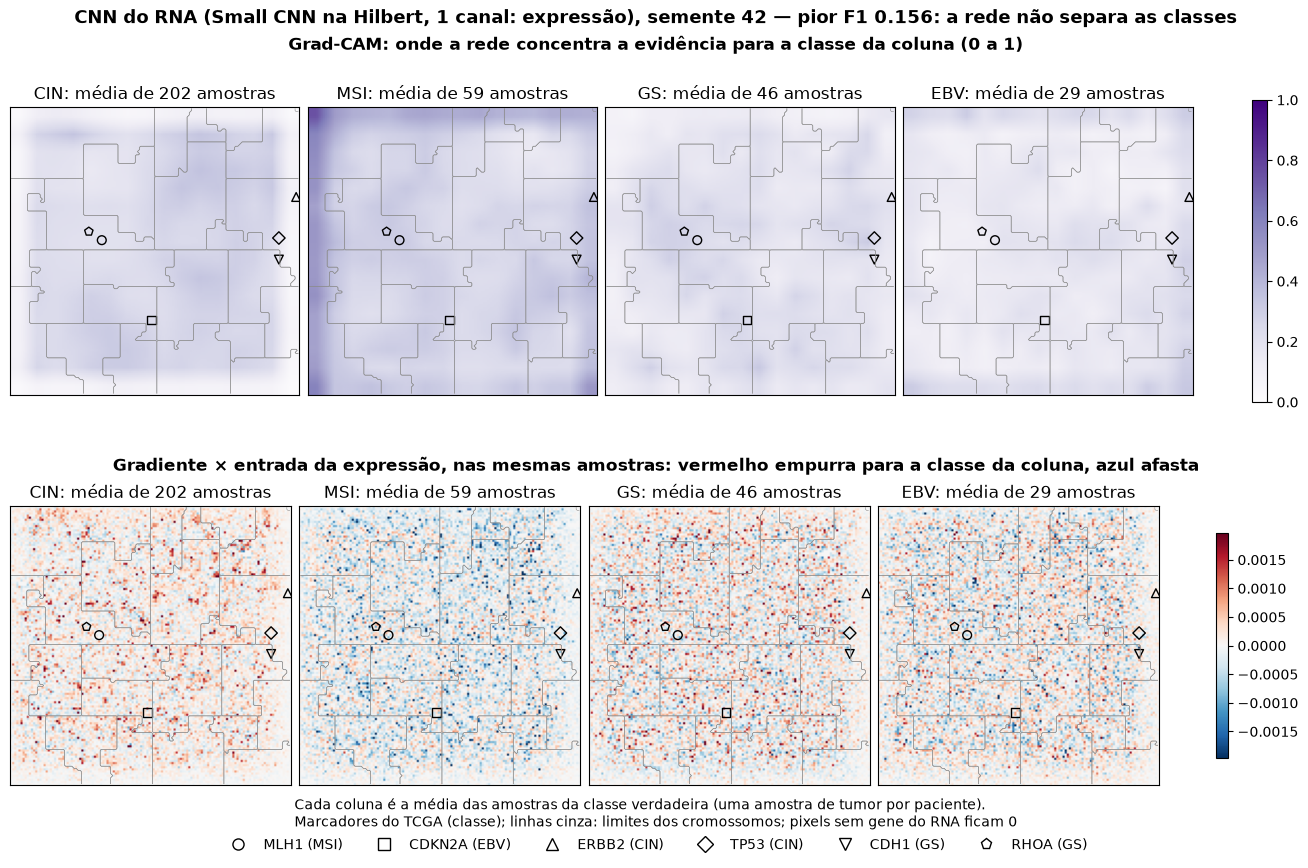

In [19]:
import matplotlib.pyplot as plt

genes_dna = pd.read_csv(INTERIM / "genes.csv")[["gene", "cromossomo"]]
assert (genes_dna.gene.to_numpy() == layout.gene.to_numpy()).all()
crom = np.full(FORMA, np.nan)
crom[layout.linha, layout.coluna] = genes_dna.cromossomo.replace({"X": "23"}).astype(int)
# marcadores do TCGA (2014), como no bloco C do 05_eval: símbolo, classe e canal do DNA em que cada um age
MARCADORES = {"MLH1": ("o", "MSI", "metilação"), "CDKN2A": ("s", "EBV", "metilação"), "ERBB2": ("^", "CIN", "CNV"),
              "TP53": ("D", "CIN", "mutação"), "CDH1": ("v", "GS", "mutação"), "RHOA": ("p", "GS", "mutação")}
pos_px = layout.set_index("gene")
n = dict(zip(CLASSES, np.bincount(y)))
CAM_MEDIO = {c: CAM[y == i].mean(axis=0) for i, c in enumerate(CLASSES)}
GXE_MEDIO = {c: GXE[y == i].mean(axis=0) for i, c in enumerate(CLASSES)}


def mapa(ax, img, **kw):
    im = ax.imshow(img, **kw)
    for k in range(1, 24):  # limites dos cromossomos
        ax.contour(crom == k, levels=[0.5], colors="0.55", linewidths=0.4)
    for g, (mk, _, _) in MARCADORES.items():
        ax.scatter(pos_px.loc[g, "coluna"], pos_px.loc[g, "linha"], marker=mk, s=40, facecolors="none", edgecolors="k", linewidths=1)
    ax.set(xticks=[], yticks=[])
    return im


pior42 = painel_completo(PO2[("CNN", SEED)])["pior F1"]
fig = plt.figure(figsize=(13, 8.6), layout="constrained")
fig.suptitle(f"CNN do RNA (Small CNN na Hilbert, 1 canal: expressão), semente 42 — pior F1 {pior42:.3f}: a rede não separa "
             "as classes", fontweight="bold", fontsize=13)
cima, baixo = fig.subfigures(2, 1)
cima.suptitle("Grad-CAM: onde a rede concentra a evidência para a classe da coluna (0 a 1)", fontweight="bold")
axs = cima.subplots(1, 4)
for i, c in enumerate(CLASSES):
    im = mapa(axs[i], CAM_MEDIO[c], cmap="Purples", vmin=0, vmax=1)
    axs[i].set_title(f"{c}: média de {n[c]} amostras")
cima.colorbar(im, ax=axs, shrink=0.8)
baixo.suptitle("Gradiente × entrada da expressão, nas mesmas amostras: vermelho empurra para a classe da coluna, azul afasta",
               fontweight="bold")
axs = baixo.subplots(1, 4)
lim = np.percentile(np.abs([GXE_MEDIO[c] for c in CLASSES]), 99.5)
for i, c in enumerate(CLASSES):
    im = mapa(axs[i], GXE_MEDIO[c], cmap="RdBu_r", vmin=-lim, vmax=lim)
    axs[i].set_title(f"{c}: média de {n[c]} amostras")
baixo.colorbar(im, ax=axs, shrink=0.8)
legenda = [plt.Line2D([], [], marker=mk, ls="", mfc="none", mec="k", ms=8, label=f"{g} ({cl})") for g, (mk, cl, _) in MARCADORES.items()]
baixo.legend(handles=legenda, loc="outside lower center", ncols=6, frameon=False,
             title="Cada coluna é a média das amostras da classe verdadeira (uma amostra de tumor por paciente).\n"
                   "Marcadores do TCGA (classe); linhas cinza: limites dos cromossomos; pixels sem gene do RNA ficam 0")
fig.savefig(RESULTS / "04_models_RNA_gradcam.png", dpi=110)
plt.show()

In [20]:
cam_gene = {c: CAM[y == i][:, LIN, COL].mean(axis=0) for i, c in enumerate(CLASSES)}  # (17.734,)
gxe_gene = {c: GXE[y == i][:, LIN, COL].mean(axis=0) for i, c in enumerate(CLASSES)}
crom_rna = genes_dna.set_index("gene").cromossomo.reindex(SIMBOLOS).to_numpy()
pd.DataFrame({"gene": SIMBOLOS, "cromossomo": crom_rna, **{f"gradcam_{c}": cam_gene[c] for c in CLASSES},
              **{f"gxe_{c}": gxe_gene[c] for c in CLASSES}}).to_csv(RESULTS / "04_models_RNA_gradcam_genes.csv", index=False)
dna = pd.read_csv(RESULTS / "05_eval_gradcam_genes.csv").set_index("gene").loc[SIMBOLOS]  # Small CNN (Hilbert), bloco C

print("1. Correlação gene a gene entre os mapas médios de Grad-CAM das classes (quanto mais alta, menos o mapa distingue as classes):")
display(pd.concat({"RNA (esta CNN)": pd.DataFrame(cam_gene).corr(),
                   "DNA (bloco C do 05_eval)": dna[[f"gradcam_{c}" for c in CLASSES]].set_axis(CLASSES, axis=1).corr()},
                  axis=1).round(2))
print("2. Na mesma classe, correlação entre o mapa do RNA e o do DNA (os 17.734 genes comuns):")
display(pd.Series({c: np.corrcoef(cam_gene[c], dna[f"gradcam_{c}"])[0, 1] for c in CLASSES}, name="r").round(2).to_frame().T)


assert all(g in SIMBOLOS for g in MARCADORES)


def percentil(v, g):
    return 100 * (v < v[SIMBOLOS.get_loc(g)]).mean()


print("3. Percentil dos marcadores entre os 17.734 genes (Grad-CAM | gradiente × entrada; 100 = o mais alto):")
display(pd.DataFrame({g: {c: f"{percentil(cam_gene[c], g):.0f} | {percentil(gxe_gene[c], g):.0f}" for c in CLASSES}
                      for g in MARCADORES}))
print("4. Os 10 genes com maior gradiente × entrada em cada classe:")
display(pd.DataFrame({c: [f"{SIMBOLOS[g]} ({crom_rna[g]})" for g in np.argsort(-gxe_gene[c])[:10]] for c in CLASSES},
                     index=range(1, 11)))
print("5. Os 5 cromossomos com maior Grad-CAM médio em cada classe:")
por_crom = pd.DataFrame(cam_gene).groupby(crom_rna).mean()
display(pd.DataFrame({c: [f"{k} ({v:.2f})" for k, v in por_crom[c].nlargest(5).items()] for c in CLASSES}, index=range(1, 6)))
log("fim do Grad-CAM da CNN do RNA")

1. Correlação gene a gene entre os mapas médios de Grad-CAM das classes (quanto mais alta, menos o mapa distingue as classes):


RNA (esta CNN)                   DNA (bloco C do 05_eval)              \
               CIN   MSI    GS   EBV                      CIN   MSI    GS   
CIN           1.00 -0.73  0.44 -0.64                     1.00  0.75  0.61   
MSI          -0.73  1.00 -0.51  0.43                     0.75  1.00  0.70   
GS            0.44 -0.51  1.00 -0.32                     0.61  0.70  1.00   
EBV          -0.64  0.43 -0.32  1.00                     0.02  0.15 -0.36   

           
      EBV  
CIN  0.02  
MSI  0.15  
GS  -0.36  
EBV  1.00

2. Na mesma classe, correlação entre o mapa do RNA e o do DNA (os 17.734 genes comuns):


,CIN,MSI,GS,EBV
r,0.56,-0.61,0.34,-0.51


3. Percentil dos marcadores entre os 17.734 genes (Grad-CAM | gradiente × entrada; 100 = o mais alto):


,MLH1,CDKN2A,ERBB2,TP53,CDH1,RHOA
CIN,34 | 45,56 | 40,11 | 51,25 | 57,22 | 37,36 | 84
MSI,69 | 63,40 | 92,79 | 69,62 | 85,56 | 70,72 | 3
GS,91 | 86,86 | 74,49 | 50,90 | 19,38 | 43,98 | 16
EBV,52 | 5,63 | 96,76 | 46,74 | 58,87 | 32,24 | 8


4. Os 10 genes com maior gradiente × entrada em cada classe:


,CIN,MSI,GS,EBV
1,LY6G6F-LY6G6D (6),CLCN5 (X),SLC5A7 (2),FN3K (17)
2,RPS10-NUDT3 (6),ONECUT3 (19),FRRS1L (9),SLC10A2 (13)
3,LY6G6D (6),ECHDC1 (6),MIR1-1HG (20),KCNJ16 (17)
4,TLX3 (5),DUSP23 (1),PHOX2A (11),PPL (16)
5,CYP4A11 (1),AAK1 (2),PYGM (11),AXIN2 (17)
6,PRLHR (10),SBNO2 (19),MRGPRD (11),NUDT19 (19)
7,CD5L (1),RPL12 (9),AARD (8),FBXO41 (2)
8,CHIA (1),TOX3 (16),ATCAY (19),OR4B1 (11)
9,TRIM43B (2),ADCY5 (3),ITPKB (1),DUSP23 (1)
10,PCDHA13 (5),TJP3 (19),LMOD3 (3),KRTAP19-8 (21)


5. Os 5 cromossomos com maior Grad-CAM médio em cada classe:


,CIN,MSI,GS,EBV
1,19 (0.29),4 (0.44),3 (0.25),14 (0.24)
2,11 (0.28),6 (0.40),10 (0.23),15 (0.23)
3,18 (0.27),1 (0.39),9 (0.22),18 (0.19)
4,13 (0.27),14 (0.32),18 (0.22),16 (0.19)
5,9 (0.26),22 (0.31),8 (0.22),13 (0.18)


13:50:03 [RAM 1702 MB, pico 1979 MB] fim do Grad-CAM da CNN do RNA


## Leitura do Grad-CAM da CNN do RNA (execução de 2026-11-16)

- **O retreino reproduziu o RNA2:** nos 5 folds, as previsões da semente 42 são as gravadas pelo RNA2 (diferença máxima
  < 1e-5), com 27 a 47 épocas e F1 macro de 0,38 a 0,60 na validação interna. Os modelos estão em `results/modelos_rna/`.
- **O Grad-CAM é baixo e difuso em todas as classes.** O mapa médio fica entre ~0,1 e ~0,45, sem uma região que se destaque. No
  MSI, ele sobe nas **bordas da imagem**, um lugar da imagem e não uma região do genoma (provável efeito do preenchimento com
  zeros das convoluções, não testado).
- **O mapa não distingue as classes pelo lugar, mas pela forma.** Entre as classes, o mapa do CIN e o do MSI têm correlação
  −0,73: um é o complemento do outro (centro × bordas). No DNA (Small CNN do bloco C), os mapas de CIN, MSI e GS se parecem
  (0,61 a 0,75). Na mesma classe, RNA × DNA: CIN 0,56, MSI −0,61, GS 0,34, EBV −0,51, o que reflete a forma do mapa (centro ×
  bordas), não os mesmos genes.
- **O gradiente × entrada não forma blocos.** Os pixels vermelhos e azuis ficam espalhados, sem as regiões contínuas do canal de
  CNV no DNA. No CIN predominam os vermelhos e no MSI os azuis: em média, a expressão empurra para o CIN e afasta do MSI, o que
  combina com as previsões espalhadas da rede (pior F1 0,156). Os 10 genes do topo de cada classe não incluem os marcadores do
  TCGA, e os percentis dos marcadores não seguem a classe (MLH1 no MSI: 69 no Grad-CAM e 63 no gradiente × entrada).
- **Leitura:** a rede não encontrou na imagem de expressão uma região que separe as classes. Isso é compatível com a hipótese do
  RNA2 (na Hilbert, genes vizinhos no genoma têm CNV parecida, mas expressão independente; a média global tira a posição de cada
  gene), mas não a testa.
- **Custo:** retreino de 11 min (11:33:59 às 11:44:36), 5 modelos, 2,1 min por fold (1,8 a 2,9); Grad-CAM e tabelas 18 s;
  `04_models_RNA` inteiro 12 min. RAM do processo 1.495 MB no início do retreino; pico 2.303 MB. Previsto: ~26 min (5,1 min por
  fold, média do RNA2) e pico abaixo de 2 GB; o fold medido foi mais curto (27 a 47 épocas) e o pico, um pouco acima.

# RNA4 — a logística hierárquica com o RNA-seq (2026-11-16)

Pré-registro no diário, 2026-11-16, "[RNA4] Pré-registro do RNA4, a logística hierárquica com o RNA-seq"; confirmado pelo usuário
("confirmo o RNA4, pode rodar").

- **Desenho (o da logística hierárquica do R11):** logística 1 com EBV, MSI e CIN+GS (todos os pacientes do treino do fold);
  logística 2 com CIN × GS (só os CIN e GS do treino). P(EBV) e P(MSI) da logística 1; P(CIN) = P1(CIN+GS) × P2(CIN) e
  P(GS) = P1(CIN+GS) × P2(GS); argmax. As duas com `treinar_logistica` (C = 1, peso balanceado), semente + fold, como no RNA1.
- **Entrada:** a principal do RNA1 (`z_fold()` do log2(TPM + 1), 17.734 genes), a mesma nas duas logísticas. Uma execução.
- **Comparação principal (pior F1):** H1 = logística hierárquica do RNA − logística hierárquica do DNA (R11, 0,772).
  Secundárias: H2 = − logística do RNA1 (0,660); H3 = − XGBoost do RNA (RNA3, 0,667; pareada por semente).

In [21]:
MSI, EBV = CLASSES.index("MSI"), CLASSES.index("EBV")
# logística hierárquica do DNA (R11, branch modelo_hierarquico; previsões em results/hier/), referência do log de acompanhamento
REF["HIER"] = ("logística hierárquica do DNA (R11)", lambda s, k: f"hier/R11_logistica_fold{k}.csv")
P_HIER_DNA = prev_ref("HIER", SEED)


def hierarquica(x_tr, y_tr, x_te, seed):
    # logística 1: 0 = EBV, 1 = MSI, 2 = CIN+GS; logística 2: 0 = CIN, 1 = GS (só os CIN e GS); devolve (p 4 classes, p1, p2)
    y1 = np.where(y_tr == EBV, 0, np.where(y_tr == MSI, 1, 2))
    p1 = treinar_logistica(x_tr, y1, x_te, seed)
    cg = np.isin(y_tr, [CIN, GS])
    p2 = treinar_logistica(x_tr[cg], (y_tr[cg] == GS).astype(int), x_te, seed)
    p = np.empty((len(x_te), len(CLASSES)))
    p[:, EBV], p[:, MSI] = p1[:, 0], p1[:, 1]
    p[:, CIN], p[:, GS] = p1[:, 2] * p2[:, 0], p1[:, 2] * p2[:, 1]
    return p, p1, p2


# autotestes: a referência do DNA tem o pior F1 do diário; a combinação soma 1 e põe cada classe no lugar, em 40 pacientes
assert abs(painel_completo(P_HIER_DNA)["pior F1"] - 0.772) < 5e-4  # diário, 2026-11-04, R11
z0 = VERSOES["principal"](fold != 0)
p, p1, p2 = hierarquica(z0[sub], y[sub], z0[sub], SEED)
assert np.allclose(p.sum(axis=1), 1, atol=1e-6) and p1.shape == (40, 3) and p2.shape == (40, 2)
assert (p.argmax(axis=1) == y[sub]).mean() > 0.9  # no próprio treino, quase tudo certo: as colunas estão no lugar
del z0, p, p1, p2
print("logística hierárquica do DNA (R11), pior F1:", round(painel_completo(P_HIER_DNA)["pior F1"], 3))

logística hierárquica do DNA (R11), pior F1: 0.772


In [22]:
P_HIER = np.empty((len(y), len(CLASSES)))
P1_CG, P2_GS = np.empty(len(y)), np.empty(len(y))  # P1(CIN+GS) e P2(GS), para descrever cada etapa
t0 = time.time()
log("=== RNA4 ===")
for k in range(K):
    arq, te = OOF / f"RNA4_hier_fold{k}.csv", fold == k
    if not arq.exists():
        log(f"RNA4 logística hierárquica · fold {k}")
        acomp(f"RNA4 logística hierárquica · fold {k}")
        x = VERSOES["principal"](~te)
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always", ConvergenceWarning)
            p, p1, p2 = hierarquica(x[~te], y[~te], x[te], SEED + k)
        if avisos:
            log(f"RNA4 · fold {k}: SEM CONVERGÊNCIA")
        pd.DataFrame(p, columns=PROBS).assign(p1_CIN_GS=p1[:, 2], p2_GS=p2[:, 1], amostra=coorte.amostra[te].to_numpy(),
                                              fold=k, classe_idx=y[te]).to_csv(arq, index=False)
        del x
        acomp(f"  fold {k} terminado")
        acomp_teste("HIER", SEED, te, p.argmax(axis=1), no_fold=True)
    d = pd.read_csv(arq).set_index("amostra").loc[coorte.amostra[te]]
    P_HIER[te], P1_CG[te], P2_GS[te] = d[PROBS].to_numpy(), d.p1_CIN_GS.to_numpy(), d.p2_GS.to_numpy()
assert np.allclose(P_HIER.sum(axis=1), 1, atol=1e-6)
log(f"RNA4 logística hierárquica: pior F1 {painel_completo(P_HIER)['pior F1']:.3f}")
acomp(f"RNA4 terminado ({len(y)} pacientes)")
acomp_teste("HIER", SEED, fold >= 0, P_HIER.argmax(axis=1), no_fold=False)
log(f"RNA4 terminado em {(time.time() - t0) / 60:.1f} min")

13:50:14 [RAM 1705 MB, pico 1979 MB] === RNA4 ===


13:50:14 [RAM 1705 MB, pico 1979 MB] RNA4 logística hierárquica: pior F1 0.660
13:50:14 [RAM 1705 MB, pico 1979 MB] RNA4 terminado em 0.0 min


In [23]:
from sklearn.metrics import f1_score, roc_auc_score

linhas4 = {"logística hierárquica do RNA (RNA4)": linha_logistica(P_HIER),
           "logística hierárquica do DNA (R11)": linha_logistica(P_HIER_DNA),
           "logística do RNA1": linha_logistica(PO["principal"]),
           "XGBoost do RNA (RNA3, 5 sementes)": linha_sementes(PO3)}
tab4 = pd.DataFrame(linhas4).T
tab4.to_csv(RESULTS / "04_models_RNA_rna4.csv")
print("n por classe:", dict(zip(CLASSES, np.bincount(y))), "· logísticas: 1 execução; XGBoost: médias das 5 sementes")
display(tab4.round(3))

# cada etapa, só descritivo: logística 1 (EBV e MSI contra o resto, pela classe prevista) e logística 2 (CIN × GS)
yp = P_HIER.argmax(axis=1)
cg = np.isin(y, [CIN, GS])
print(f"Etapa 1: F1 do EBV {f1_score(y == EBV, yp == EBV):.3f} · F1 do MSI {f1_score(y == MSI, yp == MSI):.3f} · "
      f"CIN e GS chamados de CIN+GS: {(np.isin(yp, [CIN, GS]) & cg).sum()} de {cg.sum()}")
print(f"Etapa 2: AUC CIN × GS da P2(GS) nos {cg.sum()} CIN e GS (fora do fold): {roc_auc_score(y[cg] == GS, P2_GS[cg]):.3f}")

P_XGB = {s: PO3[s] for s in SEMENTES}
COMP4 = {"H1: hierárquica do RNA − hierárquica do DNA (R11)": [(yp, P_HIER_DNA.argmax(axis=1))],
         "H2: hierárquica do RNA − logística do RNA1": [(yp, PO["principal"].argmax(axis=1))],
         "H3: hierárquica do RNA − XGBoost do RNA": [(yp, P_XGB[s].argmax(axis=1)) for s in SEMENTES]}
dif4 = pd.DataFrame({n: {m: dif_media(pares, m) for m in MET} for n, pares in COMP4.items()}).T
print("Diferença (média por semente no H3) e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):")
display(dif4)
NOMES4 = {"H1": ("a logística hierárquica do RNA", "a logística hierárquica do DNA"),
          "H2": ("a logística hierárquica do RNA", "a logística do RNA1"),
          "H3": ("a logística hierárquica do RNA", "o XGBoost do RNA")}
for n in COMP4:
    print(f"{n}: {dif4.loc[n, 'pior F1']} → {leitura2(dif4.loc[n, 'pior F1'], *NOMES4[n[:2]])}")  # mesma leitura do RNA2
log("fim do RNA4")

n por classe: {'CIN': np.int64(202), 'MSI': np.int64(59), 'GS': np.int64(46), 'EBV': np.int64(29)} · logísticas: 1 execução; XGBoost: médias das 5 sementes


,MCC,acurácia balanceada,F1 macro,pior F1,F1 CIN,F1 MSI,F1 GS,F1 EBV,AUC-PR GS,CIN → GS,GS → CIN,GS acertados,dp,mín.,máx.
logística hierárquica do RNA (RNA4),0.794,0.877,0.866,0.660,0.902,0.918,0.660,0.983,0.741,17.0,13.0,31.0,NaN,NaN,NaN
logística hierárquica do DNA (R11),0.856,0.923,0.904,0.772,0.929,0.965,0.772,0.951,0.808,16.0,6.0,39.0,NaN,NaN,NaN
logística do RNA1,0.795,0.878,0.862,0.660,0.906,0.917,0.660,0.967,0.697,18.0,11.0,32.0,NaN,NaN,NaN
"XGBoost do RNA (RNA3, 5 sementes)",0.803,NaN,NaN,0.667,0.912,0.922,0.667,0.967,0.671,12.0,15.4,29.6,0.011,0.652,0.674


Etapa 1: F1 do EBV 0.983 · F1 do MSI 0.918 · CIN e GS chamados de CIN+GS: 240 de 248
Etapa 2: AUC CIN × GS da P2(GS) nos 248 CIN e GS (fora do fold): 0.907


Diferença (média por semente no H3) e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):


,pior F1,F1 GS,F1 EBV,MCC
H1: hierárquica do RNA − hierárquica do DNA (R11),-0.113 (-0.213 a -0.023),-0.113 (-0.213 a -0.023),+0.032 (+0.000 a +0.079),-0.062 (-0.113 a -0.010)
H2: hierárquica do RNA − logística do RNA1,-0.000 (-0.037 a +0.030),-0.000 (-0.037 a +0.030),+0.016 (+0.000 a +0.049),-0.001 (-0.025 a +0.022)
H3: hierárquica do RNA − XGBoost do RNA,-0.007 (-0.078 a +0.061),-0.007 (-0.078 a +0.061),+0.016 (+0.000 a +0.049),-0.009 (-0.053 a +0.036)


H1: hierárquica do RNA − hierárquica do DNA (R11): -0.113 (-0.213 a -0.023) → a logística hierárquica do RNA fica abaixo de a logística hierárquica do DNA
H2: hierárquica do RNA − logística do RNA1: -0.000 (-0.037 a +0.030) → diferença não confirmada pelo IC 95% (a logística hierárquica do RNA fica igual de a logística do RNA1 na amostra)
H3: hierárquica do RNA − XGBoost do RNA: -0.007 (-0.078 a +0.061) → diferença não confirmada pelo IC 95% (a logística hierárquica do RNA fica abaixo de o XGBoost do RNA na amostra)
13:50:15 [RAM 1705 MB, pico 1979 MB] fim do RNA4


## Leitura do RNA4 (execução de 2026-11-16)

**Desfecho pelo pré-registro:** H1 = logística hierárquica do RNA − logística hierárquica do DNA **−0,113 (IC −0,213 a −0,023)**:
**a logística hierárquica do RNA fica abaixo da do DNA.**

| modelo | pior F1 | F1 CIN | F1 MSI | F1 GS | F1 EBV | MCC | AUC-PR GS | GS acertados | CIN → GS | GS → CIN |
|---|---|---|---|---|---|---|---|---|---|---|
| logística hierárquica do RNA (RNA4) | 0,660 | 0,902 | 0,918 | 0,660 | 0,983 | 0,794 | 0,741 | 31 | 17 | 13 |
| logística hierárquica do DNA (R11) | 0,772 | 0,929 | 0,965 | 0,772 | 0,951 | 0,856 | 0,808 | 39 | 16 | 6 |
| logística do RNA1 | 0,660 | 0,906 | 0,917 | 0,660 | 0,967 | 0,795 | 0,697 | 32 | 18 | 11 |
| XGBoost do RNA (RNA3, média de 5 sementes) | 0,667 | 0,912 | 0,922 | 0,667 | 0,967 | 0,803 | 0,671 | 29,6 | 12,0 | 15,4 |

- **Em pacientes:** contra a hierárquica do DNA, 8 GS a menos acertados (31 contra 39) e o dobro de GS chamados de CIN (13
  contra 6). O EBV fica um pouco acima no RNA (0,983 contra 0,951; +0,032, IC +0,000 a +0,079).
- **A hierarquia não ajuda o RNA (H2):** −0,000 (IC −0,037 a +0,030) contra a logística do RNA1, com 1 GS a menos e 2 GS a mais
  chamados de CIN. A ordenação dos GS melhora (AUC-PR do GS 0,741 contra 0,697), mas o corte pelo argmax fica igual. No DNA, a
  mesma hierarquia tinha subido a logística em +0,022 (IC +0,000 a +0,052).
- **H3:** contra o XGBoost do RNA, −0,007 (IC −0,078 a +0,061): diferença não confirmada pelo IC 95%, abaixo na amostra.
- **Cada etapa:** a logística 1 separa bem o EBV (F1 0,983) e o MSI (0,918), e manda 240 dos 248 CIN e GS para CIN+GS; a
  logística 2 ordena CIN × GS com AUC 0,907 nesses 248. A perda está na etapa 2, a fronteira CIN × GS, que o TCGA traçou pelo
  grau de aneuploidia, uma variável de DNA.
- **Custo:** 2,0 min de treino (12:47:33 às 12:49:30), 10 logísticas (2 por fold), ~23 s por fold; notebook inteiro 3,6 min;
  RAM do processo 1.717 MB no início do treino, pico 1.996 MB. Previsto: 2 a 3 min e pico ~2,3 GB.

# M1 e M2 — Random Forest e SVM com o RNA-seq (2026-11-16)

Pré-registro no diário, 2026-11-16, "[M1 e M2] Pré-registro do M1 (Random Forest) e do M2 (SVM), no DNA e no RNA"; confirmado
pelo usuário. Os mesmos modelos do lado do DNA (`04_models_DNA`, seção "M1 e M2"), com a entrada principal do RNA1.

- **M1 principal:** RF do RNA − RF do DNA (pares por semente). Secundária: RF do RNA − logística do RNA1.
- **M2 principal:** SVM do RNA − SVM do DNA. Secundária: SVM do RNA − logística do RNA1.
- Descritivo: ao lado do XGBoost e da MLP do RNA. No log de acompanhamento, a referência é o mesmo modelo no DNA, no mesmo fold.

In [24]:
from src.models.random_forest import treinar_random_forest
from src.models.svm import GRADE, treinar_svm

REF["RF"] = ("Random Forest do DNA (M1)", lambda s, k: f"oof_m/M1_rf_s{s}_fold{k}.csv")
REF["SVM"] = ("SVM do DNA (M2)", lambda s, k: f"oof_m/M2_svm_s{SEED}_fold{k}.csv")  # uma execução
assert all((RESULTS / REF["RF"][1](s, k)).exists() for s in SEMENTES for k in range(K))  # o lado do DNA já rodou
assert all((RESULTS / REF["SVM"][1](SEED, k)).exists() for k in range(K))
ESCOLHAS_SVM_RNA = {}


def rodar_m_rna(nome, treinar, sementes, ref):
    po = {}
    for s in sementes:
        proba, treinou = np.empty((len(y), len(CLASSES))), False
        for k in range(K):
            arq, te = OOF / f"{nome}_s{s}_fold{k}.csv", fold == k
            if not arq.exists():
                log(f"{nome} (RNA) · semente {s} · fold {k}")
                acomp(f"{nome} (RNA) · semente {s} · fold {k}")
                x = VERSOES["principal"](~te)
                r = treinar(x[~te], y[~te], x[te], s + k)
                p, escolha = (r[0], r[1]) if isinstance(r, tuple) else (r, None)
                d = pd.DataFrame(p, columns=PROBS).assign(amostra=coorte.amostra[te].to_numpy(), fold=k, classe_idx=y[te])
                if escolha:
                    d = d.assign(grau=escolha[0], C=escolha[1])
                    log(f"  {nome} (RNA) · fold {k}: escolhidos grau {escolha[0]} e C {escolha[1]}")
                d.to_csv(arq, index=False)
                del x
                treinou = True
                acomp(f"  fold {k} terminado" + (f" (grau {escolha[0]}, C {escolha[1]})" if escolha else ""))
                acomp_teste(ref, s, te, p.argmax(axis=1), no_fold=True)
            d = pd.read_csv(arq).set_index("amostra").loc[coorte.amostra[te]]
            proba[te] = d[PROBS].to_numpy()
            if "grau" in d:
                ESCOLHAS_SVM_RNA[(s, k)] = (int(d.grau.iloc[0]), float(d.C.iloc[0]))
        po[s] = proba
        log(f"{nome} (RNA) · semente {s}: pior F1 {painel_completo(proba)['pior F1']:.3f}")
        if treinou:
            acomp(f"{nome} (RNA) · semente {s} terminada ({len(y)} pacientes)")
            acomp_teste(ref, s, fold >= 0, proba.argmax(axis=1), no_fold=False)
    return po


t0 = time.time()
log("=== M1 (RNA): Random Forest ===")
PO_RF_RNA = rodar_m_rna("M1_rf", treinar_random_forest, SEMENTES, "RF")
log(f"M1 (RNA) terminado em {(time.time() - t0) / 60:.1f} min")
t0 = time.time()
log("=== M2 (RNA): SVM ===")
PO_SVM_RNA = rodar_m_rna("M2_svm", treinar_svm, [SEED], "SVM")
log(f"M2 (RNA) terminado em {(time.time() - t0) / 60:.1f} min")

13:50:15 [RAM 1707 MB, pico 1979 MB] === M1 (RNA): Random Forest ===
13:50:15 [RAM 1707 MB, pico 1979 MB] M1_rf (RNA) · semente 42 · fold 0


13:50:18 [RAM 1712 MB, pico 1979 MB] M1_rf (RNA) · semente 42 · fold 1


13:50:21 [RAM 1715 MB, pico 1979 MB] M1_rf (RNA) · semente 42 · fold 2


13:50:24 [RAM 1715 MB, pico 1979 MB] M1_rf (RNA) · semente 42 · fold 3


13:50:27 [RAM 1716 MB, pico 1979 MB] M1_rf (RNA) · semente 42 · fold 4


13:50:30 [RAM 1721 MB, pico 1979 MB] M1_rf (RNA) · semente 42: pior F1 0.646
13:50:30 [RAM 1721 MB, pico 1979 MB] M1_rf (RNA) · semente 142 · fold 0


... (24 outputs left out)

13:54:44 [RAM 1798 MB, pico 1979 MB] M2_svm (RNA) · semente 42 · fold 3


13:55:38 [RAM 1844 MB, pico 1979 MB]   M2_svm (RNA) · fold 3: escolhidos grau 1 e C 100.0
13:55:38 [RAM 1750 MB, pico 1979 MB] M2_svm (RNA) · semente 42 · fold 4


13:56:40 [RAM 1844 MB, pico 1979 MB]   M2_svm (RNA) · fold 4: escolhidos grau 1 e C 100.0


13:56:42 [RAM 1798 MB, pico 1979 MB] M2_svm (RNA) · semente 42: pior F1 0.651
13:56:42 [RAM 1798 MB, pico 1979 MB] M2 (RNA) terminado em 5.2 min


In [25]:
P_RF_DNA = {s: prev_ref("RF", s) for s in SEMENTES}
P_SVM_DNA = {SEED: prev_ref("SVM", SEED)}
linhas_m = {"Random Forest do RNA (M1)": linha_sementes(PO_RF_RNA), "Random Forest do DNA (M1)": linha_sementes(P_RF_DNA),
            "SVM do RNA (M2, 1 execução)": linha_sementes(PO_SVM_RNA), "SVM do DNA (M2, 1 execução)": linha_sementes(P_SVM_DNA),
            "XGBoost do RNA (RNA3)": linha_sementes(PO3), "MLP do RNA (RNA2)": linha_sementes(MODELOS2["MLP do RNA"]),
            "logística do RNA1 (1 execução)": linha_logistica(PO["principal"])}
tab_m = pd.DataFrame(linhas_m).T
tab_m.to_csv(RESULTS / "04_models_RNA_m1m2.csv")
print("n por classe:", dict(zip(CLASSES, np.bincount(y))), "· redes, RF e XGBoost: médias das 5 sementes")
display(tab_m.round(3))
print("SVM do RNA: grau e C escolhidos em cada fold:", {k: ESCOLHAS_SVM_RNA[(SEED, k)] for k in range(K)})

LOG1 = PO["principal"].argmax(axis=1)
COMP_M = {"M1: RF do RNA − RF do DNA": [(PO_RF_RNA[s].argmax(axis=1), P_RF_DNA[s].argmax(axis=1)) for s in SEMENTES],
          "M1: RF do RNA − logística do RNA1": [(PO_RF_RNA[s].argmax(axis=1), LOG1) for s in SEMENTES],
          "M2: SVM do RNA − SVM do DNA": [(PO_SVM_RNA[SEED].argmax(axis=1), P_SVM_DNA[SEED].argmax(axis=1))],
          "M2: SVM do RNA − logística do RNA1": [(PO_SVM_RNA[SEED].argmax(axis=1), LOG1)]}
dif_mr = pd.DataFrame({n: {m: dif_media(pares, m) for m in MET} for n, pares in COMP_M.items()}).T
print("Diferença (média por semente na RF) e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):")
display(dif_mr)
NOMES_M = {"RF do RNA": "o Random Forest do RNA", "RF do DNA": "o Random Forest do DNA", "SVM do RNA": "o SVM do RNA",
           "SVM do DNA": "o SVM do DNA", "logística do RNA1": "a logística do RNA1"}
for n in COMP_M:
    a, b = n.split(": ")[1].split(" − ")
    print(f"{n}: {dif_mr.loc[n, 'pior F1']} → {leitura2(dif_mr.loc[n, 'pior F1'], NOMES_M[a], NOMES_M[b])}")  # leitura do RNA2
log("fim do M1 e do M2 (RNA)")

n por classe: {'CIN': np.int64(202), 'MSI': np.int64(59), 'GS': np.int64(46), 'EBV': np.int64(29)} · redes, RF e XGBoost: médias das 5 sementes


,pior F1,dp,mín.,máx.,F1 CIN,F1 MSI,F1 GS,F1 EBV,MCC,AUC-PR GS,GS acertados,CIN → GS,GS → CIN,acurácia balanceada,F1 macro
Random Forest do RNA (M1),0.650,0.015,0.626,0.660,0.888,0.864,0.650,0.967,0.754,0.650,31.4,17.4,13.6,NaN,NaN
Random Forest do DNA (M1),0.695,0.012,0.680,0.714,0.912,0.829,0.695,0.979,0.781,0.739,34.0,15.8,7.4,NaN,NaN
"SVM do RNA (M2, 1 execução)",0.651,NaN,0.651,0.651,0.911,0.922,0.651,0.983,0.802,0.667,27.0,10.0,18.0,NaN,NaN
"SVM do DNA (M2, 1 execução)",0.702,NaN,0.702,0.702,0.921,0.965,0.702,0.967,0.831,0.788,33.0,15.0,12.0,NaN,NaN
XGBoost do RNA (RNA3),0.667,0.011,0.652,0.674,0.912,0.922,0.667,0.967,0.803,0.671,29.6,12.0,15.4,NaN,NaN
MLP do RNA (RNA2),0.645,0.018,0.626,0.667,0.884,0.859,0.645,0.929,0.746,0.653,31.6,18.8,12.0,NaN,NaN
logística do RNA1 (1 execução),0.660,NaN,NaN,NaN,0.906,0.917,0.660,0.967,0.795,0.697,32.0,18.0,11.0,0.878,0.862


SVM do RNA: grau e C escolhidos em cada fold: {0: (1, 1.0), 1: (1, 100.0), 2: (2, 100.0), 3: (1, 100.0), 4: (1, 100.0)}


Diferença (média por semente na RF) e IC 95% pelo bootstrap pareado (os 2.000 sorteios do 05_eval):


,pior F1,F1 GS,F1 EBV,MCC
M1: RF do RNA − RF do DNA,-0.045 (-0.138 a +0.050),-0.045 (-0.138 a +0.050),-0.013 (-0.060 a +0.029),-0.027 (-0.080 a +0.031)
M1: RF do RNA − logística do RNA1,-0.010 (-0.099 a +0.087),-0.010 (-0.099 a +0.087),+0.000 (+0.000 a +0.000),-0.041 (-0.096 a +0.016)
M2: SVM do RNA − SVM do DNA,-0.052 (-0.166 a +0.050),-0.052 (-0.166 a +0.050),+0.016 (+0.000 a +0.049),-0.029 (-0.086 a +0.024)
M2: SVM do RNA − logística do RNA1,-0.009 (-0.088 a +0.062),-0.009 (-0.088 a +0.062),+0.016 (+0.000 a +0.049),+0.007 (-0.032 a +0.043)


M1: RF do RNA − RF do DNA: -0.045 (-0.138 a +0.050) → diferença não confirmada pelo IC 95% (o Random Forest do RNA fica abaixo de o Random Forest do DNA na amostra)
M1: RF do RNA − logística do RNA1: -0.010 (-0.099 a +0.087) → diferença não confirmada pelo IC 95% (o Random Forest do RNA fica abaixo de a logística do RNA1 na amostra)
M2: SVM do RNA − SVM do DNA: -0.052 (-0.166 a +0.050) → diferença não confirmada pelo IC 95% (o SVM do RNA fica abaixo de o SVM do DNA na amostra)
M2: SVM do RNA − logística do RNA1: -0.009 (-0.088 a +0.062) → diferença não confirmada pelo IC 95% (o SVM do RNA fica abaixo de a logística do RNA1 na amostra)
13:56:44 [RAM 1798 MB, pico 1979 MB] fim do M1 e do M2 (RNA)



## Leitura do M1 e do M2 (execução de 2026-11-16)

**Desfechos pelo pré-registro:**
- **M1:** RF do RNA − RF do DNA **−0,045 (IC −0,138 a +0,050)**: diferença não confirmada pelo IC 95%; **a RF do RNA fica abaixo da do
  DNA na amostra**.
- **M2:** SVM do RNA − SVM do DNA **−0,052 (IC −0,166 a +0,050)**: diferença não confirmada pelo IC 95%; **o SVM do RNA fica abaixo do
  do DNA na amostra**.

| modelo | pior F1 | faixa entre sementes | F1 CIN | F1 MSI | F1 GS | F1 EBV | MCC | AUC-PR GS | GS acertados | CIN → GS | GS → CIN |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Random Forest do RNA (M1) | 0,650 ± 0,015 | 0,626 a 0,660 | 0,888 | 0,864 | 0,650 | 0,967 | 0,754 | 0,650 | 31,4 | 17,4 | 13,6 |
| Random Forest do DNA (M1) | 0,695 ± 0,012 | 0,680 a 0,714 | 0,912 | 0,829 | 0,695 | 0,979 | 0,781 | 0,739 | 34,0 | 15,8 | 7,4 |
| SVM do RNA (M2) | 0,651 | — | 0,911 | 0,922 | 0,651 | 0,983 | 0,802 | 0,667 | 27 | 10 | 18 |
| SVM do DNA (M2) | 0,702 | — | 0,921 | 0,965 | 0,702 | 0,967 | 0,831 | 0,788 | 33 | 15 | 12 |
| XGBoost do RNA (RNA3) | 0,667 ± 0,011 | 0,652 a 0,674 | 0,912 | 0,922 | 0,667 | 0,967 | 0,803 | 0,671 | 29,6 | 12,0 | 15,4 |
| MLP do RNA (RNA2) | 0,645 ± 0,018 | 0,626 a 0,667 | 0,884 | 0,859 | 0,645 | 0,929 | 0,746 | 0,653 | 31,6 | 18,8 | 12,0 |
| logística do RNA1 | 0,660 | — | 0,906 | 0,917 | 0,660 | 0,967 | 0,795 | 0,697 | 32 | 18 | 11 |

- **Em pacientes:** a RF do RNA acerta 2,6 GS a menos por semente e chama de CIN quase o dobro de GS (13,6 contra 7,4); o SVM do RNA
  acerta 6 GS a menos (27 contra 33) e chama de CIN 18 GS (DNA 12). A diferença da RF (0,045) é maior que a faixa entre as sementes
  da própria RF do DNA (0,680 a 0,714).
- **Secundárias:** RF do RNA − logística do RNA1 −0,010 (IC −0,099 a +0,087) e SVM do RNA − logística do RNA1 −0,009 (IC −0,088 a
  +0,062): diferenças não confirmadas pelo IC 95%, os dois abaixo da logística na amostra.
- **SVM do RNA:** grau 1 em 4 folds e grau 2 em 1; C = 100 em 4 folds e C = 1 em 1.
- **Os seis modelos de RNA que aprenderam** (logística, logística hierárquica, MLP, XGBoost, RF e SVM) **ficam entre 0,645 e 0,667**,
  sempre com o GS como pior classe; os mesmos modelos no DNA, entre 0,690 e 0,772. Em todos os pares, o RNA fica abaixo do DNA na
  amostra; o IC fica inteiro abaixo de zero na MLP (RNA2) e na logística hierárquica (RNA4), além da CNN do RNA, que não aprendeu.
- **Custo:** RF do DNA 1,2 min (25 modelos, ~3 s por fold); SVM do DNA 16,5 min (5 folds, 2,8 a 3,7 min por fold, a maior parte na CV interna de 9 configurações); RF do RNA 1,3 min; SVM do RNA 5,2 min (~1 min por fold). RAM no início do treino: 1.855 MB (`04_models_DNA`) e 1.707 MB (`04_models_RNA`); pico do notebook inteiro 2.412 MB e 1.979 MB. Notebooks inteiros: 22,6 e 8,4 min. Previsto: 45 min a 1 h 15 no total, pico ~2 GB; medido ~31 min, com a RF bem mais rápida que o previsto e o SVM do DNA no limite de cima.